#Question 2: Motion or Memory?

Everything for Question 2, in the order of the report. Run on Colab with a GPU runtime, top
to bottom.

* **Checkpoints.** Every training run saves after each epoch to `CKPT` (Google Drive on
  Colab, `./checkpoints` elsewhere). If a checkpoint already holds all 30 epochs, `train()`

* **Outputs.** Figures, GIFs and per-video results are saved to `/content/` and to `CKPT`.
* **Report items produced here:** Table 1, Figures 1, S1; Table 2, Figure 2; Table 3,
  Figures 3, 4; Table 4, Figure 5; Table 5, Table S1; Table 6, Figure 6(a), 6(b).
* **Hardware used for all reported timings:** NVIDIA RTX PRO 6000 Blackwell Server Edition.

In [1]:
%pip install torch torchvision numpy matplotlib opencv-python


## 1. Setup

### Data, split by video, and Figure 1

Loads all 10,000 videos with `split=None`, splits them by index (0–7,999 train,
8,000–8,999 validation, 9,000–9,999 test), and computes the optical flow on the first 50
training videos with the handout's exact Farneback settings. Produces Figure 1(b) and a
first version of Figure 1(a).

100%|██████████| 819M/819M [00:20<00:00, 39.5MB/s]


Loaded using torchvision.
Dataset shape: (10000, 20, 1, 64, 64)
Dataset dtype: torch.uint8
Dataset size in GiB: 0.762939453125
Train videos: 8000
Validation videos: 1000
Test videos: 1000


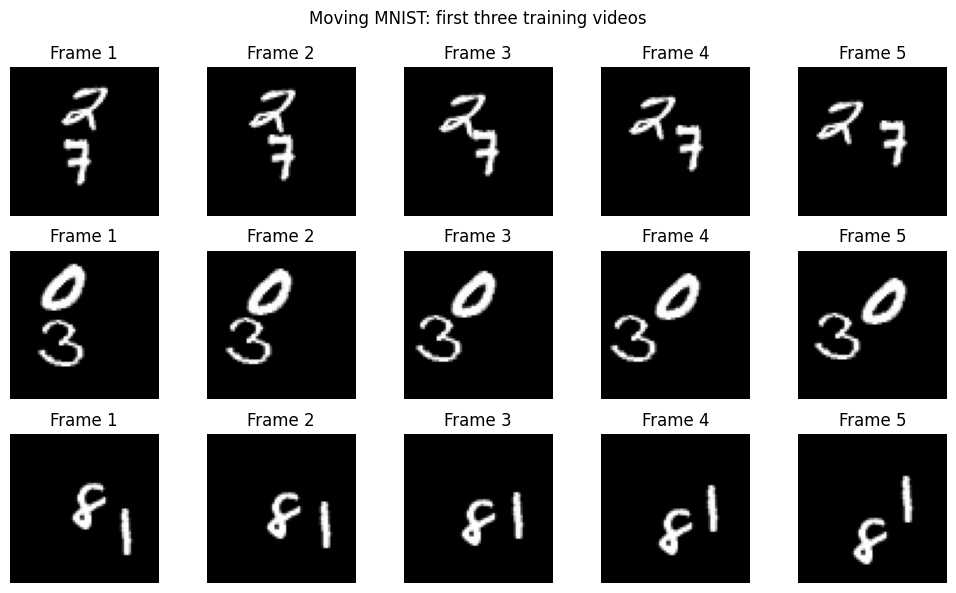

Frame pairs processed: 950
Kept pixels: 103,050
Median speed: 3.32 px/frame
Approximate 2x speed: 6.64 px/frame
Approximate 3x speed: 9.95 px/frame


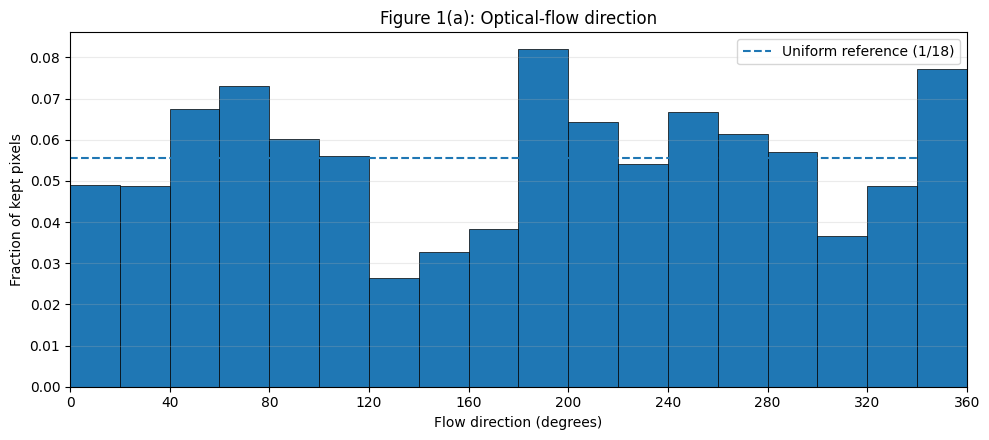

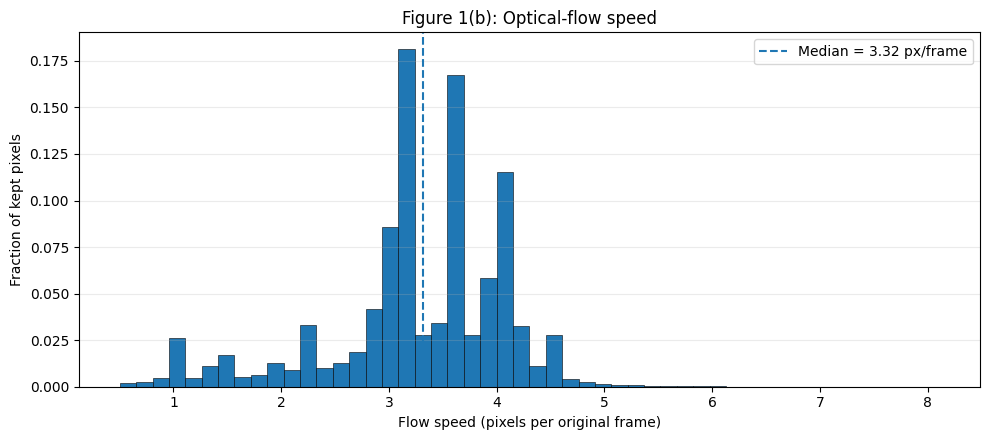

Saved:
/content/figure1a_direction.png
/content/figure1b_speed.png
/content/optical_flow_results.npz


In [2]:

from pathlib import Path
import urllib.request

import numpy as np
import torch
import matplotlib.pyplot as plt
import cv2

N_VIDEOS = 10_000
N_FRAMES = 20
H = W = 64

ROOT = Path("/content/data")
ROOT.mkdir(parents=True, exist_ok=True)

SPLITS = {
    "train": slice(0, 8000),
    "val": slice(8000, 9000),
    "test": slice(9000, 10000),
}


# Loading Moving MNIST and standardise its layout
#  output shold be (10000, 20, 1, 64, 64), uint8
def canonicalise(data):
    data = torch.as_tensor(data)

    if data.ndim == 4:
        # layouts:
        # (20, 10000, 64, 64) or (10000, 20, 64, 64)
        if tuple(data.shape) == (20, 10000, 64, 64):
            data = data.permute(1, 0, 2, 3)
        elif tuple(data.shape) != (10000, 20, 64, 64):
            raise ValueError(f"Unexpected dataset shape: {tuple(data.shape)}")

        data = data.unsqueeze(2)

    elif data.ndim == 5:
        #  allowing an existing channel dimension.
        if tuple(data.shape) == (20, 10000, 1, 64, 64):
            data = data.permute(1, 0, 2, 3, 4)
        elif tuple(data.shape) != (10000, 20, 1, 64, 64):
            raise ValueError(f"Unexpected dataset shape: {tuple(data.shape)}")
    else:
        raise ValueError(f"Unexpected number of dimensions: {data.ndim}")

    if data.dtype != torch.uint8:
        raise TypeError(
            f"Expected uint8 pixel data, got {data.dtype}. "
            "Check the dataset source before converting."
        )

    return data.contiguous()


def load_moving_mnist():
    npy_path = ROOT / "mnist_test_seq.npy"

    try:
        from torchvision.datasets import MovingMNIST

        ds = MovingMNIST(
            root=str(ROOT),
            split=None,
            download=True
        )

        data = getattr(ds, "data", None)

        if data is None:
            data = torch.stack([ds[i] for i in range(len(ds))])

        data = canonicalise(data)
        print("Loaded using torchvision.")
        return data

    except Exception as exc:
        print("Torchvision loading failed:", repr(exc))
        print("Trying the Moving MNIST .npy file.")

    # to get the original time-first array.
    if not npy_path.exists():
        url = (
            "https://www.cs.toronto.edu/"
            "~nitish/unsupervised_video/mnist_test_seq.npy"
        )
        try:
            urllib.request.urlretrieve(url, npy_path)
        except Exception as exc:
            raise RuntimeError(
                "Could not download Moving MNIST. Check Colab internet "
                "access and download mnist_test_seq.npy manually."
            ) from exc

    data = np.load(npy_path, mmap_mode="r")

    if data.shape != (20, 10000, 64, 64):
        raise ValueError(f"Unexpected .npy shape: {data.shape}")

    data = torch.from_numpy(np.array(data, dtype=np.uint8))
    data = canonicalise(data)

    print("Loaded from mnist_test_seq.npy.")
    return data


data = load_moving_mnist()

print("Dataset shape:", tuple(data.shape))
print("Dataset dtype:", data.dtype)
print("Dataset size in GiB:", data.numel() / 1024**3)

assert tuple(data.shape) == (10000, 20, 1, 64, 64)

train_videos = data[SPLITS["train"]]
val_videos = data[SPLITS["val"]]
test_videos = data[SPLITS["test"]]

print("Train videos:", len(train_videos))
print("Validation videos:", len(val_videos))
print("Test videos:", len(test_videos))

assert (len(train_videos), len(val_videos), len(test_videos)) == (8000, 1000, 1000)


fig, axes = plt.subplots(3, 5, figsize=(10, 6))

for r in range(3):
    for c in range(5):
        axes[r, c].imshow(data[r, c, 0].numpy(), cmap="gray",
                          vmin=0, vmax=255)
        axes[r, c].set_title(f"Frame {c+1}")
        axes[r, c].axis("off")

fig.suptitle("Moving MNIST: first three training videos")
plt.tight_layout()
plt.show()


# computing optical flow on first 50 trainng videos
directions = []
speeds = []

for video_idx in range(50):
    # vidoe shape: (20, 1, 64, 64), original uint8 intensities.
    video = data[video_idx, :, 0].numpy()

    for s in range(19):
        prev = video[s]
        nxt = video[s + 1]

        flow = cv2.calcOpticalFlowFarneback(
            prev, nxt, None,
            0.5, 3, 15, 3, 5, 1.2, 0
        )

        dx = flow[..., 0]
        dy = flow[..., 1]

        magnitude = np.sqrt(dx**2 + dy**2)

        # kept pixels above intensity 0.2 in BOTH frames
        # and with flow magnitude > 0.5 pixels.
        keep = (
            (prev > 51) &
            (nxt > 51) &
            (magnitude > 0.5)
        )

        if np.any(keep):
            # atan2(-dy, dx), converted to [0, 360).
            theta = np.degrees(np.arctan2(-dy[keep], dx[keep]))
            theta = theta % 360.0

            directions.append(theta)
            speeds.append(magnitude[keep])

if not directions:
    raise RuntimeError(
        "No optical-flow pixels passed the filters. "
        "Check dataset values and flow output."
    )

directions = np.concatenate(directions)
speeds = np.concatenate(speeds)

n_kept = len(speeds)
median_speed = float(np.median(speeds))

print("Frame pairs processed:", 50 * 19)
print("Kept pixels:", f"{n_kept:,}")
print("Median speed:", f"{median_speed:.3g} px/frame")
print("Approximate 2x speed:", f"{2 * median_speed:.3g} px/frame")
print("Approximate 3x speed:", f"{3 * median_speed:.3g} px/frame")


direction_edges = np.arange(0, 361, 20)
direction_counts, _ = np.histogram(
    directions, bins=direction_edges
)
direction_fraction = direction_counts / direction_counts.sum()

fig, ax = plt.subplots(figsize=(10, 4.5))

ax.bar(
    direction_edges[:-1],
    direction_fraction,
    width=20,
    align="edge",
    edgecolor="black",
    linewidth=0.5
)

ax.axhline(
    1 / 18,
    linestyle="--",
    linewidth=1.5,
    label="Uniform reference (1/18)"
)

ax.set_xlim(0, 360)
ax.set_xticks(np.arange(0, 361, 40))
ax.set_xlabel("Flow direction (degrees)")
ax.set_ylabel("Fraction of kept pixels")
ax.set_title("Figure 1(a): Optical-flow direction")
ax.legend()
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.savefig("/content/figure1a_direction.png", dpi=200)
plt.show()


fig, ax = plt.subplots(figsize=(10, 4.5))

ax.hist(
    speeds,
    bins=50,
    weights=np.ones(n_kept) / n_kept,
    edgecolor="black",
    linewidth=0.4
)

ax.axvline(
    median_speed,
    linestyle="--",
    linewidth=1.5,
    label=f"Median = {median_speed:.3g} px/frame"
)

ax.set_xlabel("Flow speed (pixels per original frame)")
ax.set_ylabel("Fraction of kept pixels")
ax.set_title("Figure 1(b): Optical-flow speed")
ax.legend()
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.savefig("/content/figure1b_speed.png", dpi=200)
plt.show()


np.savez(
    "/content/optical_flow_results.npz",
    directions=directions,
    speeds=speeds,
    direction_edges=direction_edges,
    direction_fraction=direction_fraction,
    median_speed=median_speed,
    n_kept=n_kept
)

print("Saved:")
print("/content/figure1a_direction.png")
print("/content/figure1b_speed.png")
print("/content/optical_flow_results.npz")


### 2.1 checking if  the training data already symmetric?

`run_all` produces Figure 1(a) with 95% bootstrap intervals over videos, the mirror and
rotation symmetry tests, the overlap check and the whole-pixel check. `run_full` repeats the
direction analysis on all 8,000 training videos (supplementary Figure S1).
`flow_measurement_check` shows the asymmetry comes from the data, not the flow method.

In [3]:

import numpy as np
import cv2
import matplotlib.pyplot as plt

FARNEBACK = (0.5, 3, 15, 3, 5, 1.2, 0)
EDGES = np.arange(0, 361, 20)            # 18 bins of 20°
BRIGHT = 51                              # 0.2 on the [0,1] scale



def flow_pixels(data, video_ids):
    """Kept pixels as arrays: theta (deg), speed, dx, dy, video id, overlap flag."""
    out = {k: [] for k in ("theta", "speed", "dx", "dy", "vid", "overlap")}
    n_pairs = n_overlap_pairs = 0
    for v in video_ids:
        video = np.asarray(data[v, :, 0])  # (20, 64, 64) uint8

        area = (video > BRIGHT).reshape(len(video), -1).sum(1)
        overlapping = area < 0.97 * area.max()

        for s in range(len(video) - 1):
            prev, nxt = video[s], video[s + 1]
            flow = cv2.calcOpticalFlowFarneback(prev, nxt, None, *FARNEBACK)
            dx, dy = flow[..., 0], flow[..., 1]
            mag = np.hypot(dx, dy)
            keep = (prev > BRIGHT) & (nxt > BRIGHT) & (mag > 0.5)
            n_pairs += 1
            pair_overlap = bool(overlapping[s] or overlapping[s + 1])
            n_overlap_pairs += pair_overlap
            n = int(keep.sum())
            if n == 0:
                continue
            out["theta"].append(np.degrees(np.arctan2(-dy[keep], dx[keep])) % 360.0)
            out["speed"].append(mag[keep])
            out["dx"].append(dx[keep])
            out["dy"].append(dy[keep])
            out["vid"].append(np.full(n, v))
            out["overlap"].append(np.full(n, pair_overlap))

    res = {k: np.concatenate(val) for k, val in out.items()}
    res["n_pairs"], res["n_overlap_pairs"] = n_pairs, n_overlap_pairs
    return res


def hist(theta):
    c, _ = np.histogram(np.asarray(theta) % 360.0, bins=EDGES)
    return c / c.sum()


def tv(p, q):
    """Total-variation distance: half the summed bar differences (0 = identical)."""
    return 0.5 * np.abs(p - q).sum()


def per_video_counts(theta, vid):
    return counts_by_video(theta, vid)[:, 0]


def counts_by_video(theta, vid, apply=lambda t, j: t, n=1):
    """
    C[v, j, b] = number of video v's pixels in direction bin b after applying
    the transform j times. One bincount pass, so it scales to all 8,000 videos.
    """
    ids, inv = np.unique(vid, return_inverse=True)
    C = np.zeros((len(ids), n, len(EDGES) - 1))
    for j in range(n):
        b = np.clip((np.asarray(apply(theta, j)) // 20).astype(int), 0, 17)
        C[:, j] = np.bincount(inv * 18 + b, minlength=len(ids) * 18).reshape(len(ids), 18)
    return C


def bootstrap_bars(theta, vid, B=5000, seed=0):
    rng = np.random.default_rng(seed)
    C = per_video_counts(theta, vid)  # (n_videos, 18)
    boots = np.empty((B, C.shape[1]))
    for b in range(B):
        c = C[rng.integers(len(C), size=len(C))].sum(0)
        boots[b] = c / c.sum()
    return np.percentile(boots, [2.5, 97.5], axis=0)


# further varyfing tests
# by using TV distance between the histogram and its own mirrored (or rotated)
# version. Null hypothesis: the true direction distribution is symmetric. If so,
# every video was equally likely to have occurred in mirrored (or rotated) form,
# so randomly transforming WHOLE videos produces equally plausible datasets.
# The p-value is how often those datasets look at least as lopsided as yours.
MIRROR = (lambda t, j: (180.0 - t) % 360.0 if j % 2 else t % 360.0, 2)
ROTATE = (lambda t, j: (t + 90.0 * j) % 360.0, 4)


def symmetry_test(theta, vid, group, B=5000, seed=0):
    apply, n = group
    C = counts_by_video(theta, vid, apply, n)   # (n_videos, n, 18)
    ids = np.arange(len(C))

    def stat(js):
        rows = np.arange(len(ids))
        p = C[rows, js].sum(0)
        q = C[rows, (js + 1) % n].sum(0)   # same dataset, transformed once more
        return tv(p / p.sum(), q / q.sum())

    observed = stat(np.zeros(len(ids), dtype=int))
    rng = np.random.default_rng(seed)
    null = np.array([stat(rng.integers(n, size=len(ids))) for _ in range(B)])
    return observed, (null >= observed).mean(), null



def lattice_report(dx, dy, top=8):
    """How many flow vectors sit within 0.25 px of a whole-pixel displacement?"""
    rx, ry = np.round(dx), np.round(dy)
    near = (np.abs(dx - rx) < 0.25) & (np.abs(dy - ry) < 0.25)
    print(f"  within 0.25 px of a whole-pixel move: {near.mean():.1%} of kept pixels")
    pairs, counts = np.unique(np.stack([np.abs(rx[near]), np.abs(ry[near])], 1),
                              axis=0, return_counts=True)
    order = np.argsort(-counts)[:top]
    print("  most common |dx|,|dy| (whole pixels) -> speed:")
    for i in order:
        a, b = pairs[i]
        print(f"    ({int(a)},{int(b)}) -> {np.hypot(a, b):.2f} px   "
              f"{counts[i] / near.sum():.1%}")



def run_all(data, n_videos=50, n_supp=500, B=5000, save_prefix="/content/"):
    r = flow_pixels(data, range(n_videos))
    th, vid = r["theta"], r["vid"]
    h = hist(th)
    print(f"Kept pixels: {len(th):,} from {r['n_pairs']} frame pairs "
          f"(should match your Figure 1 run)")
    print(f"Median speed: {np.median(r['speed']):.3g} px/frame")

    lo, hi = bootstrap_bars(th, vid, B)
    outside = (lo > 1 / 18) | (hi < 1 / 18)
    print(f"\n[Bootstrap over {n_videos} videos] bars whose 95% interval "
          f"excludes 1/18: {outside.sum()} of 18  "
          f"(about 1 expected by chance even if truly uniform)")
    for k in np.where(outside)[0]:
        print(f"  {EDGES[k]:3d}–{EDGES[k+1]:3d}°: {h[k]:.3f}  [{lo[k]:.3f}, {hi[k]:.3f}]")

    fig, ax = plt.subplots(figsize=(10, 4.5))
    ax.bar(EDGES[:-1], h, width=20, align="edge", edgecolor="black", linewidth=0.5)
    centres = EDGES[:-1] + 10
    ax.errorbar(centres, h, yerr=[h - lo, hi - h], fmt="none", ecolor="black",
                capsize=3, linewidth=1, label="95% bootstrap interval (over videos)")
    ax.axhline(1 / 18, linestyle="--", linewidth=1.5, color="C3",
               label="Uniform reference (1/18)")
    ax.set_xlim(0, 360); ax.set_xticks(np.arange(0, 361, 40))
    ax.set_xlabel("Flow direction θ (degrees; 0° = right, 90° = up)")
    ax.set_ylabel("Fraction of kept pixels")
    ax.set_title("Figure 1(a): Optical-flow direction")
    ax.legend(); ax.grid(axis="y", alpha=0.25)
    fig.tight_layout(); fig.savefig(save_prefix + "figure1a_direction_ci.png", dpi=200)
    plt.show()

    print("\n[Symmetry tests] TV distance between histogram and its transformed copy")
    for name, group in (("mirror  θ → 180° − θ", MIRROR), ("rotate  θ → θ + 90°", ROTATE)):
        obs, p, null = symmetry_test(th, vid, group, B)
        print(f"  {name}: observed TV = {obs:.3f}, "
              f"typical under symmetry = {np.median(null):.3f} "
              f"(95th pct {np.percentile(null, 95):.3f}), p = {p:.3f}")

    ov = r["overlap"]
    print(f"\n[Overlap] frame pairs with overlapping digits: "
          f"{r['n_overlap_pairs']} of {r['n_pairs']} "
          f"({r['n_overlap_pairs'] / r['n_pairs']:.1%}); "
          f"their share of kept pixels: {ov.mean():.1%}")
    print(f"  median speed  all: {np.median(r['speed']):.3g}   "
          f"overlap removed: {np.median(r['speed'][~ov]):.3g}   "
          f"overlap only: {np.median(r['speed'][ov]):.3g}")
    print(f"  TV(direction hist all, overlap removed) = {tv(h, hist(th[~ov])):.3f}")

    print("\n[Lattice] are the speed spikes whole-pixel moves?")
    lattice_report(r["dx"], r["dy"])

    if n_supp:
        s = flow_pixels(data, range(n_supp))
        hs = hist(s["theta"])
        print(f"\n[Supplementary, NOT Figure 1] first {n_supp} training videos:")
        print(f"  largest |bar − 1/18|: {n_videos} videos = "
              f"{np.abs(h - 1/18).max():.3f},  {n_supp} videos = "
              f"{np.abs(hs - 1/18).max():.3f}")
        for name, group in (("mirror", MIRROR), ("rotate", ROTATE)):
            obs, p, _ = symmetry_test(s["theta"], s["vid"], group, B=1000)
            print(f"  {name}: observed TV = {obs:.3f}, p = {p:.3f}")
        print(f"  median speed: {np.median(s['speed']):.3g} px/frame")
    return r


def fmt_p(p, B):
    return f"p < {1 / B:.0e}" if p == 0 else f"p = {p:.3f}"

def run_full(data, n_videos=8000, B=1000, save_prefix="/content/"):
    s = flow_pixels(data, range(n_videos))
    th, vid = s["theta"], s["vid"]
    h = hist(th)
    lo, hi = bootstrap_bars(th, vid, B)
    print(f"[Supplementary] {n_videos} training videos, {len(th):,} kept pixels")
    print(f"  median speed: {np.median(s['speed']):.3g} px/frame")
    print(f"  smallest bar: {h.min():.3f} at {EDGES[h.argmin()]}–{EDGES[h.argmin()]+20}° ({h.min()*18:.2f}x uniform)")
    print(f"  largest bar:  {h.max():.3f} at {EDGES[h.argmax()]}–{EDGES[h.argmax()]+20}° ({h.max()*18:.2f}x uniform)")
    for name, group in (("mirror", MIRROR), ("rotate", ROTATE)):
        obs, p, null = symmetry_test(th, vid, group, B)
        print(f"  {name}: observed TV = {obs:.3f}, typical under symmetry = {np.median(null):.3f}, {fmt_p(p, B)}")

    fig, ax = plt.subplots(figsize=(10, 4.5))
    ax.bar(EDGES[:-1], h, width=20, align="edge", edgecolor="black", linewidth=0.5)
    ax.errorbar(EDGES[:-1] + 10, h, yerr=[h - lo, hi - h], fmt="none", ecolor="black",
                capsize=3, linewidth=1, label="95% bootstrap interval (over videos)")
    ax.axhline(1 / 18, linestyle="--", linewidth=1.5, color="C3", label="Uniform reference (1/18)")
    ax.set_xlim(0, 360); ax.set_xticks(np.arange(0, 361, 40))
    ax.set_xlabel("Flow direction θ (degrees; 0° = right, 90° = up)")
    ax.set_ylabel("Fraction of kept pixels")
    ax.set_title(f"Supplementary: flow direction over {n_videos} training videos")
    ax.legend(); ax.grid(axis="y", alpha=0.25)
    fig.tight_layout(); fig.savefig(save_prefix + f"supp_direction_{n_videos}.png", dpi=200)
    plt.show()
    return s


Kept pixels: 103,050 from 950 frame pairs (should match your Figure 1 run)
Median speed: 3.32 px/frame

[Bootstrap over 50 videos] bars whose 95% interval excludes 1/18: 4 of 18  (about 1 expected by chance even if truly uniform)
  120–140°: 0.026  [0.018, 0.036]
  140–160°: 0.033  [0.019, 0.049]
  160–180°: 0.038  [0.025, 0.053]
  300–320°: 0.037  [0.023, 0.053]


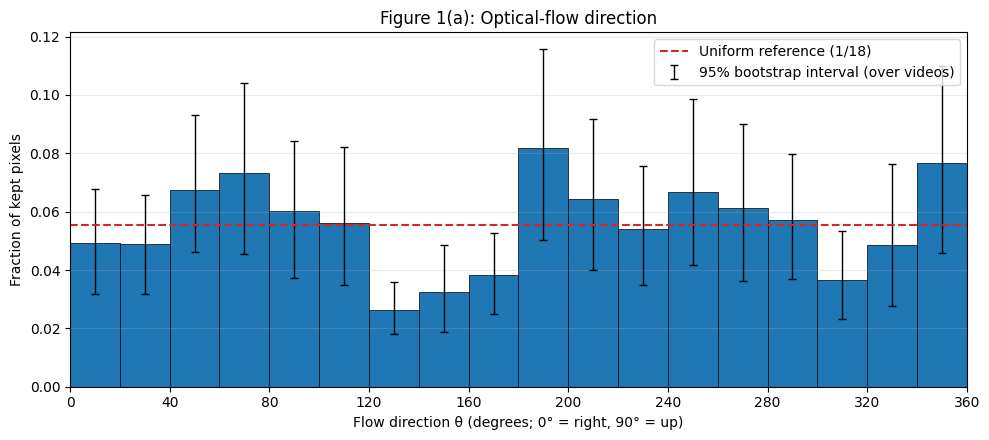


[Symmetry tests] TV distance between histogram and its transformed copy
  mirror  θ → 180° − θ: observed TV = 0.132, typical under symmetry = 0.083 (95th pct 0.134), p = 0.055
  rotate  θ → θ + 90°: observed TV = 0.200, typical under symmetry = 0.129 (95th pct 0.217), p = 0.080

[Overlap] frame pairs with overlapping digits: 315 of 950 (33.2%); their share of kept pixels: 34.7%
  median speed  all: 3.32   overlap removed: 3.28   overlap only: 3.34
  TV(direction hist all, overlap removed) = 0.028

[Lattice] are the speed spikes whole-pixel moves?
  within 0.25 px of a whole-pixel move: 74.8% of kept pixels
  most common |dx|,|dy| (whole pixels) -> speed:
    (3,2) -> 3.61 px   14.1%
    (1,3) -> 3.16 px   13.1%
    (3,1) -> 3.16 px   11.5%
    (2,3) -> 3.61 px   9.0%
    (1,4) -> 4.12 px   7.6%
    (4,1) -> 4.12 px   6.2%
    (0,3) -> 3.00 px   5.0%
    (0,4) -> 4.00 px   4.6%

[Supplementary, NOT Figure 1] first 500 training videos:
  largest |bar − 1/18|: 50 videos = 0.029,  500 vid

In [4]:
r = run_all(data)

[Supplementary] 8000 training videos, 16,443,567 kept pixels
  median speed: 3.32 px/frame
  smallest bar: 0.040 at 140–160° (0.72x uniform)
  largest bar:  0.067 at 220–240° (1.21x uniform)
  mirror: observed TV = 0.071, typical under symmetry = 0.007, p < 1e-03
  rotate: observed TV = 0.079, typical under symmetry = 0.010, p < 1e-03


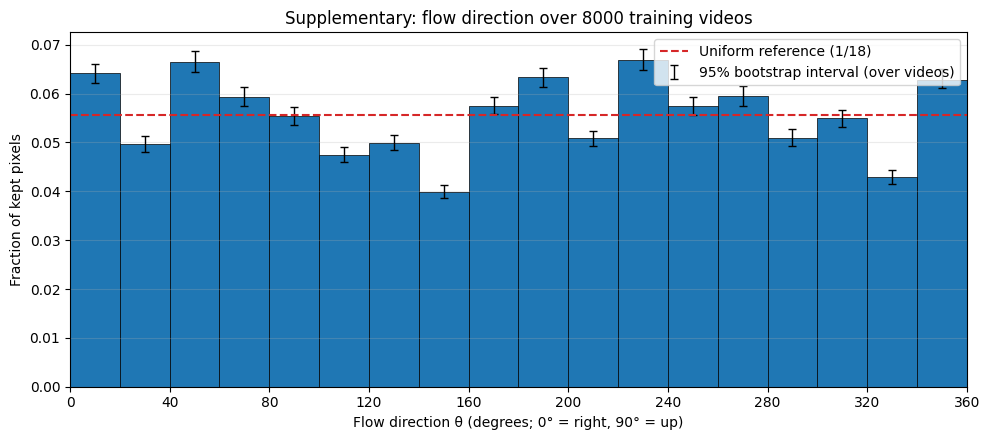

In [5]:
s = run_full(data)

In [6]:
def flow_measurement_check(data, n_videos=500, B=1000):
    d = np.asarray(data[:n_videos])                              # (n, 20, 1, 64, 64) uint8
    r0 = flow_pixels(d, range(n_videos))
    h0 = hist(r0["theta"])

    dm = np.ascontiguousarray(d[..., ::-1])                      # mirror: column j -> 63 - j
    dr = np.ascontiguousarray(np.rot90(d, 1, axes=(-2, -1)))     # = torch.rot90(k=1, dims=(-2,-1))
    tm = (180.0 - flow_pixels(dm, range(n_videos))["theta"]) % 360.0   # undo mirror
    tr = (flow_pixels(dr, range(n_videos))["theta"] - 90.0) % 360.0    # undo rotation
    print(f"[Flow-method check, {n_videos} videos]  (near 0 = method is not the cause)")
    print(f"  TV(original, mirror -> flow -> unmirror) = {tv(h0, hist(tm)):.4f}")
    print(f"  TV(original, rotate -> flow -> unrotate) = {tv(h0, hist(tr)):.4f}")

    #  180° turn will keep every motion AXIS (up-right stays on the up-right/down-left line).
    # If the asymmetry is an axis preference, this test should NOT reject.
    HALF_TURN = (lambda t, j: (t + 180.0 * j) % 360.0, 2)
    obs, p, null = symmetry_test(r0["theta"], r0["vid"], HALF_TURN, B)
    print(f"[180° turn symmetry] observed TV = {obs:.3f}, "
          f"typical under symmetry = {np.median(null):.3f}, {fmt_p(p, B)}")

flow_measurement_check(data)

[Flow-method check, 500 videos]  (near 0 = method is not the cause)
  TV(original, mirror -> flow -> unmirror) = 0.0001
  TV(original, rotate -> flow -> unrotate) = 0.0004
[180° turn symmetry] observed TV = 0.045, typical under symmetry = 0.029, p = 0.072


### Table 1: transformation and window checks

Defines mirror, rotation, the 8 symmetries `G`, the windows at each speed and the allowed
start frames, and checks them on synthetic tensors. Every later experiment uses these
functions.

In [7]:
import torch

N_T = 20

def mirror(x):
    """(Mx)[i, j] = x[i, 63 - j]: flip the columns."""
    return torch.flip(x, dims=(-1,))

def rotate(x, a=1):
    """R^a: rotate 90° anticlockwise a times (a may be negative)."""
    return torch.rot90(x, k=a % 4, dims=(-2, -1))

# The 8 symmetries of the square as (m, a). (M R^a)(x) = M(R^a(x)): rotate first, then mirror.
G = [(m, a) for m in (0, 1) for a in range(4)]

def apply_g(x, g):
    m, a = g
    y = rotate(x, a)
    return mirror(y) if m else y

def invert_g(x, g):
    """R^a is undone by R^-a; each M R^a is its own inverse."""
    m, a = g
    return apply_g(x, g) if m else rotate(x, -a)

def allowed_starts(k, speed_augmented):
    if speed_augmented:  # models C, D: all 5 inputs and at least 2 targets exist
        return [t for t in range(1, N_T + 1) if t + 6 * k <= N_T]
    return [t for t in range(1, N_T + 1) if t + 9 * k <= N_T]   # models A, B: all 5 targets

def window(video, t, k=1):
    """
    video: (20, ...) with frames numbered 1..20 along dim 0.
    Returns X (5, ...); Y (5, ...) with missing targets zero-filled; valid (5,) bool;
    and the input / existing target frame numbers.
    """
    in_f = [t + k * i for i in range(5)]
    tgt_f = [t + k * (5 + i) for i in range(5)]
    assert in_f[-1] <= N_T, f"input frame {in_f[-1]} does not exist"
    dev = video.device
    valid = torch.tensor([f <= N_T for f in tgt_f], device=dev)
    X = video.index_select(0, torch.tensor(in_f, device=dev) - 1)
    Y = video.index_select(0, torch.tensor([min(f, N_T) for f in tgt_f], device=dev) - 1)
    Y = Y * valid.view(5, *[1] * (Y.dim() - 1)).to(Y.dtype)   # zero out missing targets
    return X, Y, valid, in_f, [f for f, ok in zip(tgt_f, valid.tolist()) if ok]

torch.manual_seed(0)
x = torch.rand(20, 1, 64, 64)
p = torch.zeros(20, 1, 64, 64); p[7, 0, 10, 20] = 1

def maxdiff(a, b):
    return (a - b).abs().max().item(), torch.equal(a, b)

def bright(t):
    f, _, i, j = torch.nonzero(t)[0].tolist()
    return (f, i, j)

numbered = torch.arange(1, N_T + 1, dtype=torch.float32).view(N_T, 1, 1, 1).expand(N_T, 1, 64, 64)
def frames_used(k):
    X, Y, valid, _, _ = window(numbered, 1, k)
    return ([int(v) for v in X[:, 0, 0, 0].tolist()],
            [int(v) for v in Y[valid][:, 0, 0, 0].tolist()])

rows = []
for name, lhs, rhs in [
    ("(a) max|M(M(x)) − x|", mirror(mirror(x)), x),
    ("(b) max|R^4(x) − x|", rotate(rotate(rotate(rotate(x)))), x),
    ("(c) max|MRM(x) − R^-1(x)|", mirror(rotate(mirror(x))), torch.rot90(x, k=-1, dims=(-2, -1))),
]:
    d, eq = maxdiff(lhs, rhs)
    rows.append((name, "0", f"{d:g} (torch.equal: {eq})", d == 0 and eq))

for name, got, exp in [("(d) bright pixel of M(p)", bright(mirror(p)), (7, 10, 43)),
                       ("(e) bright pixel of R(p)", bright(rotate(p)), (7, 43, 10))]:
    rows.append((name, str(exp), str(got), got == exp))

for name, k, exp in [("(f) 1× input / target", 1, (list(range(1, 6)), list(range(6, 11)))),
                     ("(g) 2× input / target", 2, ([1, 3, 5, 7, 9], [11, 13, 15, 17, 19])),
                     ("(h) 3× input / target", 3, ([1, 4, 7, 10, 13], [16, 19]))]:
    got = frames_used(k)
    fmt = lambda pr: f"{', '.join(map(str, pr[0]))} / {', '.join(map(str, pr[1]))}"
    rows.append((name, fmt(exp), fmt(got), got == exp))

print(f"{'Check':30s} {'Expected':34s} {'Yours':34s} OK")
for name, exp, got, ok in rows:
    print(f"{name:30s} {exp:34s} {got:34s} {'✓' if ok else '✗  <-- FIX'}")

inv_ok = all(torch.equal(invert_g(apply_g(x, g), g), x) for g in G)
imgs = torch.stack([apply_g(x[0, 0], g) for g in G])
distinct = all(not torch.equal(imgs[i], imgs[j]) for i in range(8) for j in range(i + 1, 8))
starts_ok = (allowed_starts(1, False) == list(range(1, 12)) and
             allowed_starts(1, True) == list(range(1, 15)) and
             allowed_starts(2, True) == list(range(1, 9)) and
             allowed_starts(3, True) == [1, 2])
print(f"\nEvery g undone by its inverse: {inv_ok}")
print(f"The 8 elements of G are 8 different transformations: {distinct}")
print(f"Allowed start frames match the handout: {starts_ok}")
print("\nALL CHECKS PASS" if all(r[3] for r in rows) and inv_ok and distinct and starts_ok
      else "\nSOMETHING FAILED: fix before continuing")

Check                          Expected                           Yours                              OK
(a) max|M(M(x)) − x|           0                                  0 (torch.equal: True)              ✓
(b) max|R^4(x) − x|            0                                  0 (torch.equal: True)              ✓
(c) max|MRM(x) − R^-1(x)|      0                                  0 (torch.equal: True)              ✓
(d) bright pixel of M(p)       (7, 10, 43)                        (7, 10, 43)                        ✓
(e) bright pixel of R(p)       (7, 43, 10)                        (7, 43, 10)                        ✓
(f) 1× input / target          1, 2, 3, 4, 5 / 6, 7, 8, 9, 10     1, 2, 3, 4, 5 / 6, 7, 8, 9, 10     ✓
(g) 2× input / target          1, 3, 5, 7, 9 / 11, 13, 15, 17, 19 1, 3, 5, 7, 9 / 11, 13, 15, 17, 19 ✓
(h) 3× input / target          1, 4, 7, 10, 13 / 16, 19           1, 4, 7, 10, 13 / 16, 19           ✓

Every g undone by its inverse: True
The 8 elements of G are 8 different

## 2. Baseline: model A

### Model

ConvLSTM without any peepholes: one convolution produced all four gates, two layers with 64
hidden channels, a 9 step rolled out with the model's own predictions fed back and no teacher
forcing. `patch` and `dilations` are only changed for model D; the defaults are model A.

In [8]:
#  model A
import os, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU")

class ConvLSTMCell(nn.Module):
    """One ConvLSTM layer without peepholes: a single conv produces all four gates."""
    def __init__(self, in_ch, hid_ch, k=3, dilation=1):
        super().__init__()
        self.conv = nn.Conv2d(in_ch + hid_ch, 4 * hid_ch, k,
                              padding=dilation * (k // 2), dilation=dilation, bias=True)

    def forward(self, u, h, c):
        i, f, o, g = self.conv(torch.cat([u, h], dim=1)).chunk(4, dim=1)
        c = torch.sigmoid(f) * c + torch.sigmoid(i) * torch.tanh(g)
        h = torch.sigmoid(o) * torch.tanh(c)
        return h, c

class ConvLSTMForecaster(nn.Module):
    """Model A with the default settings; patch / dilations are the knobs for model D."""
    def __init__(self, patch=4, hid=64, k=3, dilations=(1, 1)):
        super().__init__()
        self.patch, self.hid, self.k, self.dilations = patch, hid, k, tuple(dilations)
        ch = patch * patch
        self.cell1 = ConvLSTMCell(ch, hid, k, dilations[0])
        self.cell2 = ConvLSTMCell(hid, hid, k, dilations[1])
        self.head = nn.Conv2d(hid, ch, 1, bias=True)

    def step(self, frame, state):
        (h1, c1), (h2, c2) = state
        u = F.pixel_unshuffle(frame, self.patch)
        h1, c1 = self.cell1(u, h1, c1)
        h2, c2 = self.cell2(h1, h2, c2)
        x = torch.sigmoid(F.pixel_shuffle(self.head(h2), self.patch))
        return x, ((h1, c1), (h2, c2))

    def forward(self, X):
        B, _, _, H, W = X.shape
        z = X.new_zeros(B, self.hid, H // self.patch, W // self.patch)
        state = ((z, z), (z, z))
        outs, x_hat = [], None
        for tau in range(9):
            u = X[:, tau] if tau < 5 else x_hat
            x_hat, state = self.step(u, state)
            if tau >= 4:
                outs.append(x_hat)
        return torch.stack(outs, dim=1)

def n_params(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)

_m = ConvLSTMForecaster()
print(f"model A parameters: {n_params(_m):,} (expected 480,784)")
assert n_params(_m) == 480_784
with torch.no_grad():
    print("output shape:", tuple(_m(torch.rand(2, 5, 1, 64, 64)).shape))
del _m

device: NVIDIA RTX PRO 6000 Blackwell Server Edition
model A parameters: 480,784 (expected 480,784)
output shape: (2, 5, 1, 64, 64)


### Windows, loss and training

One random window per video per epoch, missing targets masked out of the loss, Adam
(lr 1e-3), batch 32, 30 epochs, seeds 0 and 1. The sampler is checked against `window()`
before any training.

In [9]:
TRAIN_U8 = data[:8000].to(device)      # uint8 on the GPU (~0.65 GB)
VAL_U8   = data[8000:9000]
TEST_U8  = data[9000:10000]

def sample_windows(vids_u8, idx, gen, speed_aug=False, sym_aug=False, return_meta=False):
    """One random window per video in idx. Missing targets are zero-filled and marked invalid."""
    B = len(idx)
    if speed_aug:
        k = torch.randint(1, 4, (B,), generator=gen)      # k in {1,2,3}
        n_starts = 20 - 6 * k                              # 14, 8, 2 allowed starts
    else:
        k = torch.ones(B, dtype=torch.long)
        n_starts = torch.full((B,), 11)                    # t in 1..11
    t = 1 + (torch.rand(B, generator=gen) * n_starts).long()
    steps = torch.arange(5)
    in_f  = t[:, None] + k[:, None] * steps                # frame numbers, 1-based
    tgt_f = t[:, None] + k[:, None] * (steps + 5)
    valid = (tgt_f <= 20).to(vids_u8.device)
    v = idx[:, None].to(vids_u8.device)
    X = vids_u8[v, (in_f - 1).to(vids_u8.device)].float() / 255
    Y = vids_u8[v, (tgt_f.clamp(max=20) - 1).to(vids_u8.device)].float() / 255
    Y = Y * valid[:, :, None, None, None]
    if sym_aug:                                            # same g for input and target
        g_idx = torch.randint(0, 8, (B,), generator=gen).to(vids_u8.device)
        for gi, g in enumerate(G):
            m = g_idx == gi
            if m.any():
                X[m] = apply_g(X[m], g)
                Y[m] = apply_g(Y[m], g)
    return (X, Y, valid, k, t) if return_meta else (X, Y, valid)

def masked_mse(pred, Y, valid):
    """Mean over pixels and EXISTING target frames of each video, then over videos."""
    per_frame = ((pred - Y) ** 2).mean(dim=(2, 3, 4))      # (B, 5)
    v = valid.float()
    return ((per_frame * v).sum(1) / v.sum(1)).mean()

def check_sampler():
    gen = torch.Generator().manual_seed(123)
    for speed_aug in (False, True):
        idx = torch.randint(0, 8000, (2000,), generator=gen)
        X, Y, valid, k, t = sample_windows(TRAIN_U8, idx, gen, speed_aug, return_meta=True)
        ks = (1, 2, 3) if speed_aug else (1,)
        allowed = {(kk, tt) for kk in ks for tt in allowed_starts(kk, speed_aug)}
        seen = set(zip(k.tolist(), t.tolist()))
        assert seen == allowed, f"start frames differ from the handout: {sorted(seen ^ allowed)}"
        for r in range(50):
            Xr, Yr, vr, _, _ = window(TRAIN_U8[int(idx[r])], int(t[r]), int(k[r]))
            assert torch.equal(X[r], Xr.float() / 255) and torch.equal(Y[r], Yr.float() / 255)
            assert torch.equal(valid[r], vr)
        del X, Y
    print("sampler matches window() and the allowed start frames: OK")

check_sampler()

def set_seed(seed):
    torch.manual_seed(seed); np.random.seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def sync():
    if device.type == "cuda":
        torch.cuda.synchronize()

@torch.no_grad()
def val_loss(model, vids_u8, bs=200):
    """E(5) on the validation videos at 1x, t=1. For monitoring only."""
    model.eval(); total = 0.0
    for s in range(0, len(vids_u8), bs):
        v = vids_u8[s:s + bs].to(device).float() / 255
        ok = torch.ones(len(v), 5, dtype=torch.bool, device=device)
        total += masked_mse(model(v[:, 0:5]), v[:, 5:10], ok).item() * len(v)
    model.train()
    return total / len(vids_u8)

def train(make_model, seed, name, speed_aug=False, sym_aug=False,
          epochs=30, bs=32, lr=1e-3, ckpt_dir=None):
    """Handout protocol. The seed controls init, shuffling, windows and augmentation."""
    set_seed(seed)
    model = make_model().to(device)                  # created after seeding, so init depends on the seed
    gen = torch.Generator().manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    start, epoch_times, history = 0, [], []
    path = f"{ckpt_dir}/{name}_seed{seed}.pt" if ckpt_dir else None
    if path and os.path.exists(path):                # resume after a Colab disconnect
        ck = torch.load(path, map_location="cpu", weights_only=False)
        model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"])
        gen.set_state(ck["gen"]); start = ck["epoch"]
        epoch_times, history = ck["epoch_times"], ck["history"]
        print(f"resuming {name} seed {seed} from epoch {start}")
    model.train()
    for ep in range(start, epochs):
        perm = torch.randperm(8000, generator=gen)
        running = torch.zeros((), device=device)
        sync(); t0 = time.perf_counter()
        for s in range(0, 8000, bs):
            idx = perm[s:s + bs]
            X, Y, valid = sample_windows(TRAIN_U8, idx, gen, speed_aug, sym_aug)
            loss = masked_mse(model(X), Y, valid)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            running += loss.detach() * len(idx)
        sync(); epoch_times.append(time.perf_counter() - t0)   # training pass only
        vl = val_loss(model, VAL_U8)
        history.append((running.item() / 8000, vl))
        print(f"{name} seed {seed} | epoch {ep + 1:2d}/{epochs} | train {history[-1][0]:.5f} "
              f"| val E(5) {vl:.5f} | {epoch_times[-1]:.1f} s")
        if path:
            torch.save({"model": model.state_dict(), "opt": opt.state_dict(),
                        "gen": gen.get_state(), "epoch": ep + 1,
                        "epoch_times": epoch_times, "history": history}, path)
    return model, {"epoch_time": float(np.mean(epoch_times)), "history": history}

sampler matches window() and the allowed start frames: OK


In [10]:
# train model A, seeds 0 and 1
try:
    from google.colab import drive
    drive.mount("/content/drive")
    CKPT = "/content/drive/MyDrive/dl4stg_q2_v2"
except ImportError:
    CKPT = "./checkpoints"
os.makedirs(CKPT, exist_ok=True)

models_A, info_A = {}, {}
for seed in (0, 1):
    models_A[seed], info_A[seed] = train(ConvLSTMForecaster, seed, "A", ckpt_dir=CKPT)
    print(f"seed {seed}: mean training time per epoch {info_A[seed]['epoch_time']:.1f} s\n")

Mounted at /content/drive
A seed 0 | epoch  1/30 | train 0.04610 | val E(5) 0.03931 | 3.8 s
A seed 0 | epoch  2/30 | train 0.03966 | val E(5) 0.03854 | 1.6 s
A seed 0 | epoch  3/30 | train 0.03868 | val E(5) 0.03750 | 1.6 s
A seed 0 | epoch  4/30 | train 0.03720 | val E(5) 0.03552 | 1.5 s
A seed 0 | epoch  5/30 | train 0.03546 | val E(5) 0.03399 | 1.5 s
A seed 0 | epoch  6/30 | train 0.03378 | val E(5) 0.03237 | 1.5 s
A seed 0 | epoch  7/30 | train 0.03238 | val E(5) 0.03132 | 1.5 s
A seed 0 | epoch  8/30 | train 0.03125 | val E(5) 0.03036 | 1.5 s
A seed 0 | epoch  9/30 | train 0.03039 | val E(5) 0.02977 | 1.5 s
A seed 0 | epoch 10/30 | train 0.02973 | val E(5) 0.02935 | 1.6 s
A seed 0 | epoch 11/30 | train 0.02936 | val E(5) 0.02877 | 1.5 s
A seed 0 | epoch 12/30 | train 0.02868 | val E(5) 0.02932 | 1.5 s
A seed 0 | epoch 13/30 | train 0.02843 | val E(5) 0.02778 | 1.5 s
A seed 0 | epoch 14/30 | train 0.02794 | val E(5) 0.02750 | 1.5 s
A seed 0 | epoch 15/30 | train 0.02748 | val E(5) 

### Table 2: model A against Blank and Copy-last

In [11]:
def windows_all(vids_u8, k=1, t=1):
    """The same window for every video (evaluation)."""
    in_f = [t + k * i for i in range(5)]
    tgt_f = [t + k * (5 + i) for i in range(5)]
    valid = torch.tensor([f <= 20 for f in tgt_f])
    return (vids_u8[:, [f - 1 for f in in_f]],
            vids_u8[:, [min(f, 20) - 1 for f in tgt_f]], valid)

@torch.no_grad()
def predict(predictor, X_u8, bs=32):
    if isinstance(predictor, nn.Module):
        predictor.eval()
    out = []
    for s in range(0, len(X_u8), bs):
        out.append(predictor(X_u8[s:s + bs].to(device).float() / 255).cpu())
    return torch.cat(out)

def per_video_mse(pred, Y_u8, valid):
    """(videos, 5): MSE per video and horizon; NaN where the target frame doesn't exist."""
    m = ((pred - Y_u8.float() / 255) ** 2).mean(dim=(2, 3, 4))
    m[:, ~valid] = float("nan")
    return m

blank = lambda X: torch.zeros_like(X)
copy_last = lambda X: X[:, -1:].expand(-1, 5, -1, -1, -1).clone()

def fmt(v):
    return f"{v:.2e}" if abs(v) < 1e-3 else f"{v:.3g}"

def horizon_summary(m):
    h = torch.nanmean(m, dim=0).tolist()        # MSE_1..MSE_5, averaged over videos
    return h + [float(np.mean(h))]              # plus E(5)

Xt, Yt, valid1 = windows_all(TEST_U8, k=1, t=1)
mse = {f"A{s}": per_video_mse(predict(models_A[s], Xt), Yt, valid1) for s in (0, 1)}
mse["Blank"] = per_video_mse(predict(blank, Xt), Yt, valid1)
mse["Copy-last"] = per_video_mse(predict(copy_last, Xt), Yt, valid1)

sA = [horizon_summary(mse["A0"]), horizon_summary(mse["A1"])]
pA = n_params(models_A[0])
print(f"{'':10s}" + "".join(f"{c:>26s}" for c in ["MSE1", "MSE2", "MSE3", "MSE4", "MSE5", "E(5)"]) + "    params")
print(f"{'Model A':10s}" + "".join(
    f"{fmt(np.mean([sA[0][i], sA[1][i]])) + ' (' + fmt(sA[0][i]) + ', ' + fmt(sA[1][i]) + ')':>26s}"
    for i in range(6)) + f"    {pA:,}")
for name in ("Blank", "Copy-last"):
    s = horizon_summary(mse[name])
    print(f"{name:10s}" + "".join(f"{fmt(v):>26s}" for v in s) + "    0")

torch.save({"mse": mse, "info_A": info_A}, f"{CKPT}/table2_results.pt")

                                MSE1                      MSE2                      MSE3                      MSE4                      MSE5                      E(5)    params
Model A        0.017 (0.0171, 0.017)   0.0205 (0.0208, 0.0201)   0.0227 (0.0232, 0.0223)    0.0245 (0.025, 0.0239)   0.0261 (0.0267, 0.0256)   0.0222 (0.0225, 0.0218)    480,784
Blank                         0.0426                    0.0426                    0.0426                    0.0425                    0.0425                    0.0426    0
Copy-last                     0.0492                    0.0604                    0.0669                    0.0708                    0.0732                    0.0641    0


In [12]:
def fmt(v):
    return f"{v:.2e}" if abs(v) < 1e-3 else f"{v:#.3g}"

sA = [horizon_summary(mse["A0"]), horizon_summary(mse["A1"])]
col_A  = [f"{fmt((a + b) / 2)} ({fmt(a)}, {fmt(b)})" for a, b in zip(*sA)]
col_Bl = [fmt(v) for v in horizon_summary(mse["Blank"])]
col_Cl = [fmt(v) for v in horizon_summary(mse["Copy-last"])]
names = [f"$\\mathrm{{MSE}}_{h}$" for h in range(1, 6)] + ["$E^{(5)}$"]

print(r"\begin{table}[H]")
print(r"\centering")
print(r"\caption{Test error at $1\times$, $t=1$. Model A: mean (seed 0, seed 1).}")
print(r"\label{tab:table2}")
print(r"\begin{tabular}{lccc}")
print(r"\toprule")
print(r" & Model A & Blank & Copy-last \\")
print(r"\midrule")
for n, a, b, c in zip(names, col_A, col_Bl, col_Cl):
    print(f"{n} & {a} & {b} & {c} \\\\")
print(r"\midrule")
print(f"Parameters & {n_params(models_A[0]):,} & 0 & 0 \\\\".replace(",", "{,}"))
print(r"\bottomrule")
print(r"\end{tabular}")
print(r"\end{table}")
print("\nMean training time per epoch (s):",
      f"{np.mean([info_A[0]['epoch_time'], info_A[1]['epoch_time']]):.3g}",
      f"({info_A[0]['epoch_time']:.3g}, {info_A[1]['epoch_time']:.3g})")

\begin{table}[H]
\centering
\caption{Test error at $1\times$, $t=1$. Model A: mean (seed 0, seed 1).}
\label{tab:table2}
\begin{tabular}{lccc}
\toprule
 & Model A & Blank & Copy-last \\
\midrule
$\mathrm{MSE}_1$ & 0.0170 (0.0171, 0.0170) & 0.0426 & 0.0492 \\
$\mathrm{MSE}_2$ & 0.0205 (0.0208, 0.0201) & 0.0426 & 0.0604 \\
$\mathrm{MSE}_3$ & 0.0227 (0.0232, 0.0223) & 0.0426 & 0.0669 \\
$\mathrm{MSE}_4$ & 0.0245 (0.0250, 0.0239) & 0.0425 & 0.0708 \\
$\mathrm{MSE}_5$ & 0.0261 (0.0267, 0.0256) & 0.0425 & 0.0732 \\
$E^{(5)}$ & 0.0222 (0.0225, 0.0218) & 0.0426 & 0.0641 \\
\midrule
Parameters & 480{,}784 & 0 & 0 \\
\bottomrule
\end{tabular}
\end{table}

Mean training time per epoch (s): 1.54 (1.58, 1.49)


### Figure 2: three test videos, one with overlapping digits

test videos shown (index within test split): [7, 12, 0] -> last one has overlap


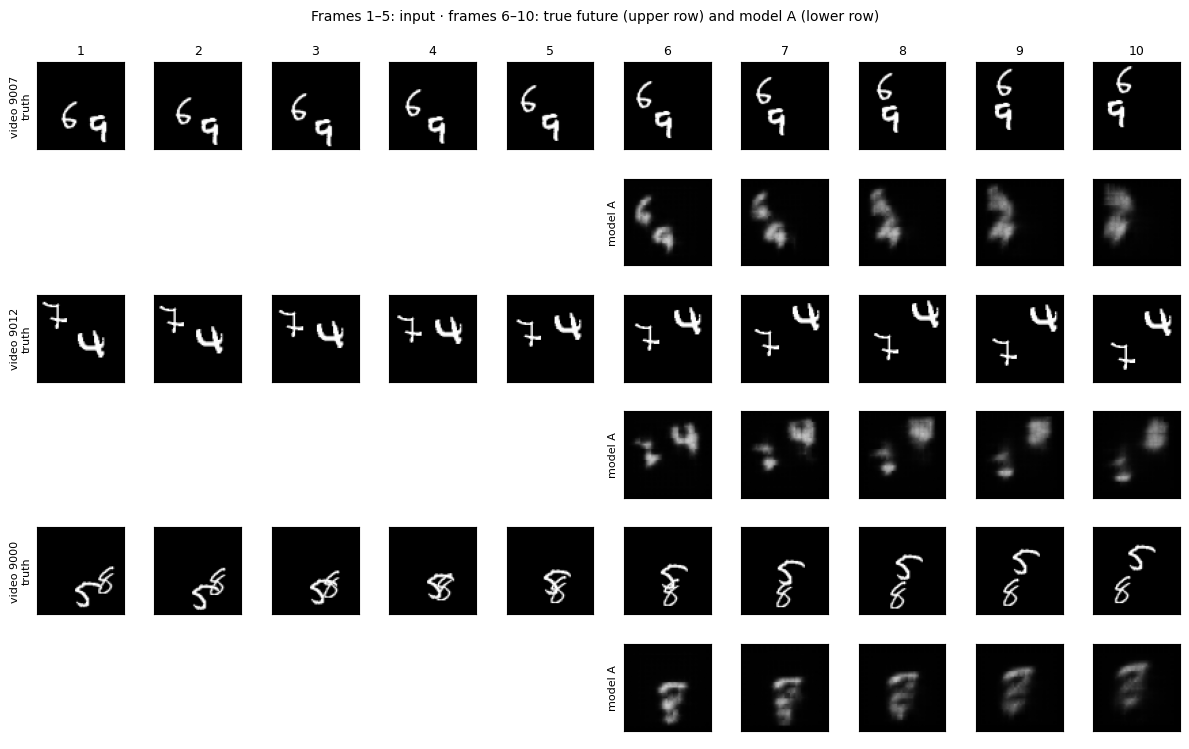

In [13]:
import matplotlib.pyplot as plt

area = (TEST_U8[:, :10, 0] > 51).flatten(2).sum(-1).float()          # (1000, 10)
full = (TEST_U8[:, :, 0] > 51).flatten(2).sum(-1).max(1).values.float()
overlap_in_future = (area[:, 5:10] < 0.97 * full[:, None]).any(1)
clean = (area < 0.97 * full[:, None]).sum(1) == 0
chosen = [int(torch.nonzero(clean)[0]), int(torch.nonzero(clean)[1]),
          int(torch.nonzero(overlap_in_future)[0])]
print("test videos shown (index within test split):", chosen, "-> last one has overlap")

pred0 = predict(models_A[0], Xt[chosen])
fig, axes = plt.subplots(6, 10, figsize=(12, 7.6))
for r, v in enumerate(chosen):
    truth = torch.cat([Xt[v], Yt[v]]).float() / 255
    for c in range(10):
        axes[2 * r, c].imshow(truth[c, 0], cmap="gray", vmin=0, vmax=1)
        if c >= 5:
            axes[2 * r + 1, c].imshow(pred0[r, c - 5, 0], cmap="gray", vmin=0, vmax=1)
        for ax in (axes[2 * r, c], axes[2 * r + 1, c]):
            ax.set_xticks([]); ax.set_yticks([])
        if c < 5:
            axes[2 * r + 1, c].axis("off")
        if r == 0:
            axes[0, c].set_title(f"{c + 1}", fontsize=9)
    axes[2 * r, 0].set_ylabel(f"video {9000 + v}\ntruth", fontsize=8)
    axes[2 * r + 1, 5].set_ylabel("model A", fontsize=8)
fig.suptitle("Frames 1–5: input · frames 6–10: true future (upper row) and model A (lower row)",
             fontsize=10)
fig.tight_layout()
fig.savefig("/content/figure2_modelA.png", dpi=200)
fig.savefig(f"{CKPT}/figure2_modelA.png", dpi=200)
plt.show()

## 3. Testing the baseline

### Table 3: mirror and rotation tests

Consistency gap $C_T$ and transformed error $E_T$ per test video. Blank and Copy-last must
be exactly consistent, and model A's $E^{(5)}$ must match Table 2.

In [14]:
TRANSFORMS = {"M": mirror, "R": rotate}      # R = 90° anticlockwise
Y01 = Yt.float() / 255                        # true futures in [0,1]

def fmt(v):
    if v == 0:
        return "0"
    return f"{v:.2e}" if abs(v) < 1e-3 else f"{v:#.3g}"

def per_video(a, b):
    """Squared error per video, averaged over pixels and all 5 horizons -> (N,)."""
    return ((a - b) ** 2).mean(dim=(1, 2, 3, 4))

@torch.no_grad()
def consistency_tests(predictor, keep=False):
    fX = predict(predictor, Xt)
    out = {"E5": per_video(fX, Y01)}
    if keep:
        out["fX"] = fX
    for name, T in TRANSFORMS.items():
        fTX = predict(predictor, T(Xt))             # predict on the transformed video
        out[f"C{name}"] = per_video(fTX, T(fX))     # vs transforming the normal prediction
        out[f"E{name}"] = per_video(fTX, T(Y01))    # vs the true transformed future
        if keep:
            out[f"fTX_{name}"] = fTX
    return out

res = {"A0": consistency_tests(models_A[0], keep=True),   # seed 0 is kept for the figures
       "A1": consistency_tests(models_A[1]),
       "Blank": consistency_tests(blank),
       "Copy-last": consistency_tests(copy_last)}

for name in ("Blank", "Copy-last"):
    for T in "MR":
        assert res[name][f"C{T}"].max().item() == 0, f"{name} should be exactly consistent"
        assert abs(res[name][f"E{T}"].mean() - res[name]["E5"].mean()) < 1e-6
assert abs(res["A0"]["E5"].mean().item() - horizon_summary(mse["A0"])[-1]) < 1e-6
print("checks passed: Blank and Copy-last exactly consistent, E(5) matches Table 2\n")

avg = lambda name, key: res[name][key].mean().item()
rows3 = [("E5", "$E^{(5)}$"), ("CM", "$C_M$"), ("EM", "$E_M$"),
         ("CR", "$C_R$"), ("ER", "$E_R$")]
print(r"\begin{table}[H]")
print(r"\centering")
print(r"\caption{Mirror and rotation tests at $1\times$, $t=1$. Model A: mean (seed 0, seed 1).}")
print(r"\label{tab:table3}")
print(r"\begin{tabular}{lccc}")
print(r"\toprule")
print(r" & Model A & Blank & Copy-last \\")
print(r"\midrule")
for key, label in rows3:
    a0, a1 = avg("A0", key), avg("A1", key)
    print(f"{label} & {fmt((a0 + a1) / 2)} ({fmt(a0)}, {fmt(a1)}) & "
          f"{fmt(avg('Blank', key))} & {fmt(avg('Copy-last', key))} \\\\")
print(r"\bottomrule")
print(r"\end{tabular}")
print(r"\end{table}")

#  fr Q2.6-Q2.8
e5 = np.mean([avg("A0", "E5"), avg("A1", "E5")])
for T in "MR":
    eT = np.mean([avg("A0", f"E{T}"), avg("A1", f"E{T}")])
    cT = np.mean([avg("A0", f"C{T}"), avg("A1", f"C{T}")])
    print(f"\nModel A, {'mirror' if T == 'M' else 'rotation'}: E_{T}/E(5) = {eT / e5:.3f}, "
          f"C_{T}/E_{T} = {cT / eT:.3f}")

torch.save({k: {m: v[m] for m in ("E5", "CM", "EM", "CR", "ER")} for k, v in res.items()},
           f"{CKPT}/table3_per_video.pt")

checks passed: Blank and Copy-last exactly consistent, E(5) matches Table 2

\begin{table}[H]
\centering
\caption{Mirror and rotation tests at $1\times$, $t=1$. Model A: mean (seed 0, seed 1).}
\label{tab:table3}
\begin{tabular}{lccc}
\toprule
 & Model A & Blank & Copy-last \\
\midrule
$E^{(5)}$ & 0.0222 (0.0225, 0.0218) & 0.0426 & 0.0641 \\
$C_M$ & 0.00190 (0.00180, 0.00201) & 0 & 0 \\
$E_M$ & 0.0228 (0.0232, 0.0224) & 0.0426 & 0.0641 \\
$C_R$ & 0.00321 (0.00340, 0.00301) & 0 & 0 \\
$E_R$ & 0.0238 (0.0242, 0.0234) & 0.0426 & 0.0641 \\
\bottomrule
\end{tabular}
\end{table}

Model A, mirror: E_M/E(5) = 1.028, C_M/E_M = 0.083

Model A, rotation: E_R/E(5) = 1.074, C_R/E_R = 0.135


### Figure 3 (and GIFs): the two largest mirror gaps and the two largest rotation gaps

Figure 3 videos (transform, test index): [('M', 257), ('M', 347), ('R', 390), ('R', 168)]


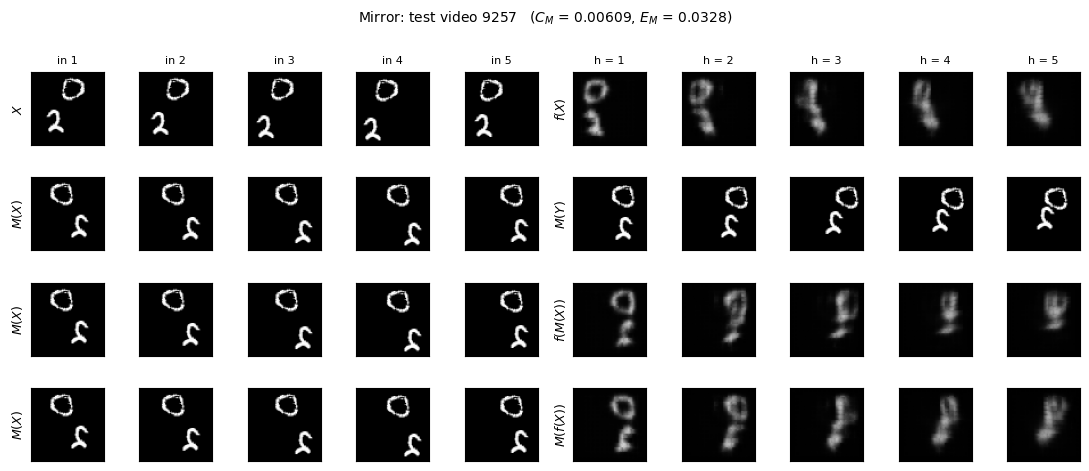

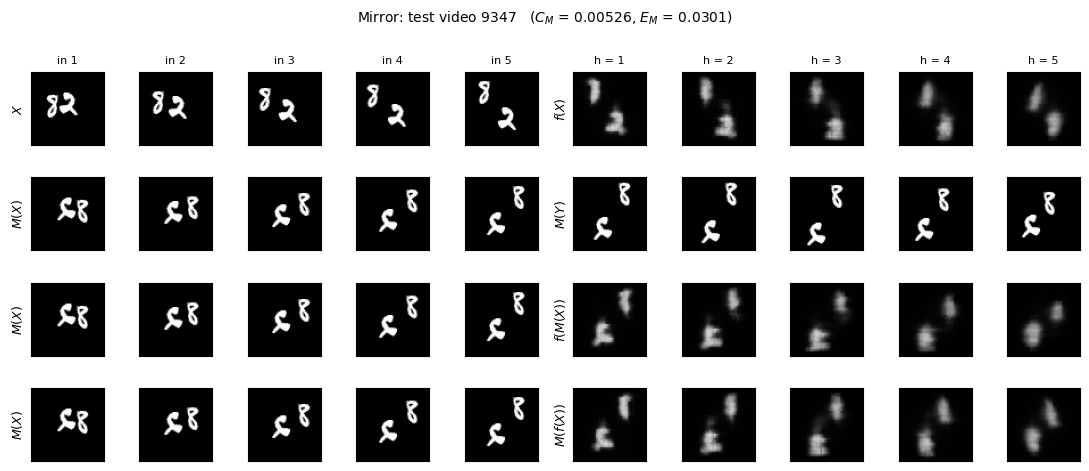

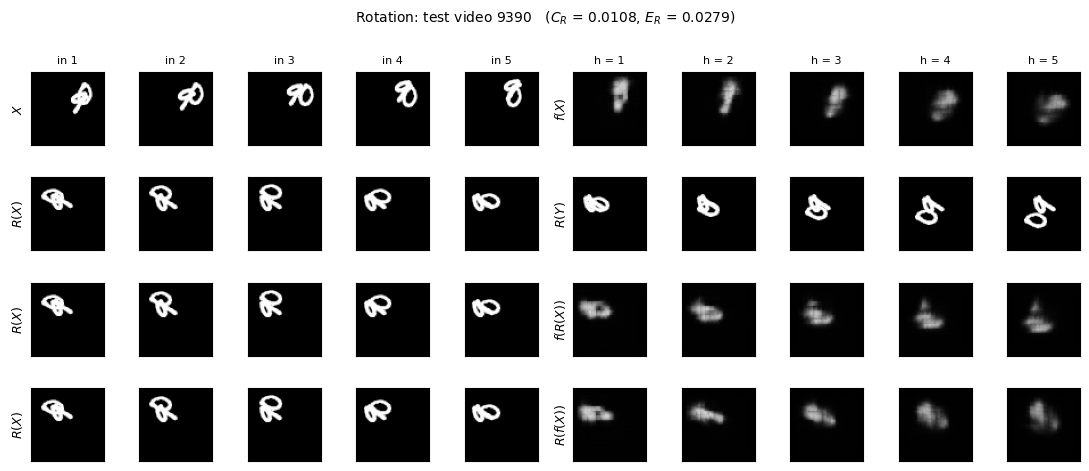

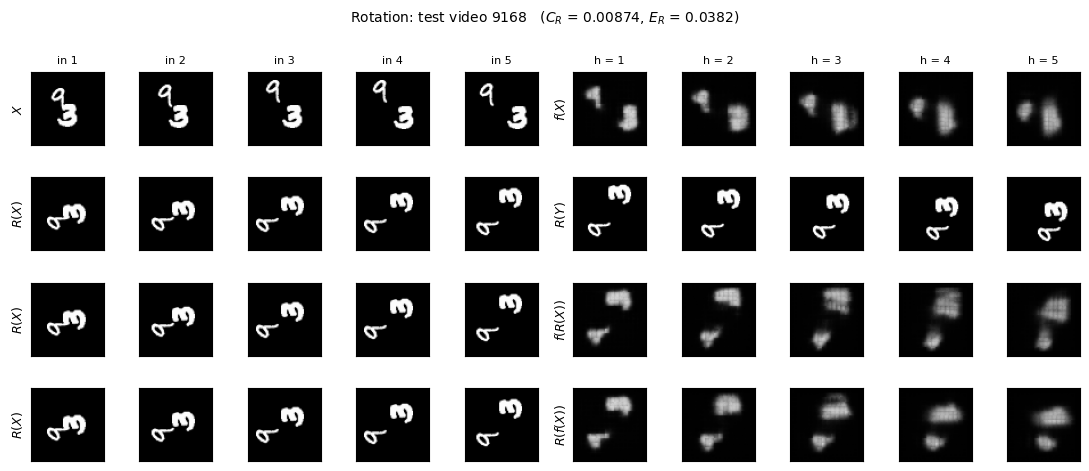

GIFs saved:
  /content/drive/MyDrive/dl4stg_q2_v2/gifs/fig3_M_video9257.gif
  /content/drive/MyDrive/dl4stg_q2_v2/gifs/fig3_M_video9347.gif
  /content/drive/MyDrive/dl4stg_q2_v2/gifs/fig3_R_video9390.gif
  /content/drive/MyDrive/dl4stg_q2_v2/gifs/fig3_R_video9168.gif


In [15]:
from PIL import Image

r0 = res["A0"]
picks = []
for name in ("M", "R"):
    top = torch.argsort(r0[f"C{name}"], descending=True)[:2].tolist()
    picks += [(name, v) for v in top]
print("Figure 3 videos (transform, test index):", picks)
torch.save(picks, f"{CKPT}/fig3_picks.pt")              # Figure 6(a) must reuse these

GIF_DIR = f"{CKPT}/gifs"
os.makedirs(GIF_DIR, exist_ok=True)

def panel_rows(name, v):
    T = TRANSFORMS[name]
    X, Y = Xt[v].float() / 255, Y01[v]
    fX, fTX = r0["fX"][v], r0[f"fTX_{name}"][v]
    TX = T(X)
    rows = [(X, fX), (TX, T(Y)), (TX, fTX), (TX, T(fX))]
    labels = [("$X$", "$f(X)$"), (f"${name}(X)$", f"${name}(Y)$"),
              (f"${name}(X)$", f"$f({name}(X))$"), (f"${name}(X)$", f"${name}(f(X))$")]
    return rows, labels

def fig_to_image(fig):
    fig.canvas.draw()
    img = Image.fromarray(np.asarray(fig.canvas.buffer_rgba())[..., :3].copy())
    plt.close(fig)
    return img

gif_paths = []
for name, v in picks:
    rows, labels = panel_rows(name, v)
    word = "Mirror" if name == "M" else "Rotation"

    fig, axes = plt.subplots(4, 10, figsize=(11, 4.9))
    for i, ((left, right), (ll, rl)) in enumerate(zip(rows, labels)):
        for c in range(10):
            img = left[c, 0] if c < 5 else right[c - 5, 0]
            axes[i, c].imshow(img, cmap="gray", vmin=0, vmax=1)
            axes[i, c].set_xticks([]); axes[i, c].set_yticks([])
        axes[i, 0].set_ylabel(ll, fontsize=9)
        axes[i, 5].set_ylabel(rl, fontsize=9)
    for c in range(10):
        axes[0, c].set_title(f"in {c + 1}" if c < 5 else f"h = {c - 4}", fontsize=8)
    fig.suptitle(f"{word}: test video {9000 + v}   "
                 f"($C_{name}$ = {fmt(r0[f'C{name}'][v].item())}, "
                 f"$E_{name}$ = {fmt(r0[f'E{name}'][v].item())})", fontsize=10)
    fig.tight_layout()
    png = f"fig3_{name}_video{9000 + v}.png"
    fig.savefig(f"/content/{png}", dpi=200); fig.savefig(f"{CKPT}/{png}", dpi=200)
    plt.show()

    #  GIF->steps through the 5 horizons, same 4 rows
    frames = []
    for h in range(5):
        fig, axes = plt.subplots(4, 1, figsize=(2.8, 9.2))
        for ax, (_, right), (_, rl) in zip(axes, rows, labels):
            ax.imshow(right[h, 0], cmap="gray", vmin=0, vmax=1)
            ax.set_title(rl, fontsize=10); ax.set_xticks([]); ax.set_yticks([])
        fig.suptitle(f"video {9000 + v} · {word.lower()} · horizon {h + 1}", fontsize=9)
        fig.tight_layout()
        frames.append(fig_to_image(fig))
    path = f"{GIF_DIR}/fig3_{name}_video{9000 + v}.gif"
    frames[0].save(path, save_all=True, append_images=frames[1:], duration=800, loop=0)
    gif_paths.append(path)

print("GIFs saved:", *gif_paths, sep="\n  ")

### Figure 4: per-video consistency gaps

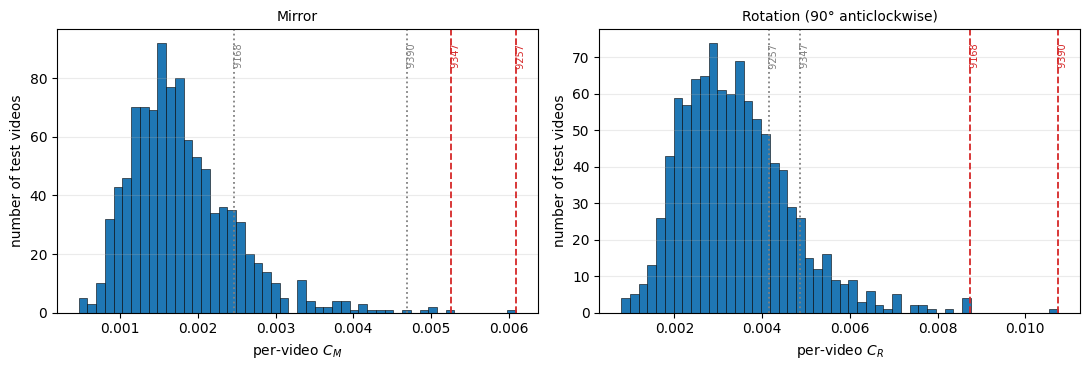

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, name in zip(axes, ("M", "R")):
    c = r0[f"C{name}"].numpy()
    ax.hist(c, bins=50, color="C0", edgecolor="black", linewidth=0.4)
    top = ax.get_ylim()[1]
    for t_name, v in picks:
        own = t_name == name
        ax.axvline(c[v], color="C3" if own else "grey", ls="--" if own else ":", lw=1.3)
        ax.text(c[v], top * 0.95, f" {9000 + v}", rotation=90, va="top", fontsize=7,
                color="C3" if own else "grey")
    ax.set_xlabel(f"per-video $C_{name}$")
    ax.set_ylabel("number of test videos")
    ax.set_title("Mirror" if name == "M" else "Rotation (90° anticlockwise)", fontsize=10)
    ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig("/content/figure4_consistency_hist.png", dpi=200)
fig.savefig(f"{CKPT}/figure4_consistency_hist.png", dpi=200)
plt.show()

### Numbers for Q2.7 and Q2.8

In [17]:
#  numbers for Q2.7 and Q2.8
cM, cR = r0["CM"].numpy(), r0["CR"].numpy()
print(f"correlation between per-video C_M and C_R: {np.corrcoef(cM, cR)[0, 1]:.2f}")
print(f"videos where the rotation gap is larger than the mirror gap: {np.mean(cR > cM):.0%}")

# Is rotation reliably harder? Paired bootstrap over test videos, averaged over both seeds.
d = np.mean([(res[s]["ER"] - res[s]["EM"]).numpy() for s in ("A0", "A1")], axis=0)
rng = np.random.default_rng(0)
boot = np.array([d[rng.integers(0, len(d), len(d))].mean() for _ in range(5000)])
lo, hi = np.percentile(boot, [2.5, 97.5])
print(f"E_R - E_M = {d.mean():.2e}, 95% interval [{lo:.2e}, {hi:.2e}]")

# checking if the big gaps overlap videos?
area = (TEST_U8[:, :10, 0] > 51).flatten(2).sum(-1).float()
full = (TEST_U8[:, :, 0] > 51).flatten(2).sum(-1).max(1).values.float()
ovl = (area < 0.97 * full[:, None]).any(1).numpy()
print(f"\nvideos with overlap somewhere in frames 1-10: {ovl.mean():.0%}")
for name, c in (("M", cM), ("R", cR)):
    top50 = np.argsort(-c)[:50]
    print(f"C_{name}: mean with overlap {c[ovl].mean():.2e}, without {c[~ovl].mean():.2e}; "
          f"overlap share among the 50 largest gaps: {ovl[top50].mean():.0%}")

# Per-horizon detail for the Figure 3 videos
print("\nFigure 3 videos, per horizon (brightness = total intensity / true future's)")
for name, v in picks:
    T = TRANSFORMS[name]
    TY, fTX, TfX = T(Y01[v]), r0[f"fTX_{name}"][v], T(r0["fX"][v])
    ch = ((fTX - TfX) ** 2).mean(dim=(1, 2, 3)).numpy()
    bright = lambda z: (z.sum(dim=(1, 2, 3)) / TY.sum(dim=(1, 2, 3))).numpy()
    print(f"  {name}, video {9000 + v} (overlap: {bool(ovl[v])})")
    print("    gap C per horizon  ", " ".join(f"{x:.2e}" for x in ch))
    print("    brightness, row 3  ", " ".join(f"{x:.2f}" for x in bright(fTX)))
    print("    brightness, row 4  ", " ".join(f"{x:.2f}" for x in bright(TfX)))

correlation between per-video C_M and C_R: 0.39
videos where the rotation gap is larger than the mirror gap: 94%
E_R - E_M = 1.00e-03, 95% interval [8.94e-04, 1.10e-03]

videos with overlap somewhere in frames 1-10: 73%
C_M: mean with overlap 1.79e-03, without 1.83e-03; overlap share among the 50 largest gaps: 72%
C_R: mean with overlap 3.36e-03, without 3.53e-03; overlap share among the 50 largest gaps: 80%

Figure 3 videos, per horizon (brightness = total intensity / true future's)
  M, video 9257 (overlap: False)
    gap C per horizon   2.54e-03 4.01e-03 6.63e-03 8.30e-03 8.97e-03
    brightness, row 3   1.16 1.15 1.05 0.90 0.97
    brightness, row 4   1.26 1.23 1.18 1.14 1.20
  M, video 9347 (overlap: False)
    gap C per horizon   1.34e-03 3.52e-03 5.99e-03 8.19e-03 7.25e-03
    brightness, row 3   1.16 1.15 1.11 1.02 0.97
    brightness, row 4   1.15 1.18 1.16 1.09 1.02
  R, video 9390 (overlap: True)
    gap C per horizon   2.62e-03 6.98e-03 1.22e-02 1.59e-02 1.60e-02
    bright

### Table 4: faster motion

In [18]:
#  speed test (Table 4)
preds = {"A0": models_A[0], "A1": models_A[1], "Copy-last": copy_last, "Blank": blank}
speed_res = {}   # (name, k) -> per-video MSE, shape (1000, 5), NaN where no target exists
for k in (1, 2, 3):
    Xk, Yk, vk = windows_all(TEST_U8, k=k, t=1)
    print(f"{k}x: input frames {[1 + k * i for i in range(5)]}, "
          f"scored targets {[1 + k * (5 + i) for i in range(5) if 1 + k * (5 + i) <= 20]}")
    for name, p in preds.items():
        speed_res[(name, k)] = per_video_mse(predict(p, Xk), Yk, vk)

def E(name, k, H):
    """Average over the first H horizons, then over the 1,000 test videos."""
    m = speed_res[(name, k)][:, :H]
    assert not torch.isnan(m).any(), f"{name} at {k}x has no target for some of the first {H} horizons"
    return m.mean().item()

#  checks against Table 2
for s in (0, 1):
    t2 = horizon_summary(mse[f"A{s}"])
    assert abs(E(f"A{s}", 1, 5) - t2[-1]) < 1e-6
    assert abs(E(f"A{s}", 1, 2) - (t2[0] + t2[1]) / 2) < 1e-6
print("checks passed: 1x numbers match Table 2\n")

rows4 = [(2, 1), (2, 2), (2, 3), (5, 1), (5, 2)]
print(r"\begin{table}[H]")
print(r"\centering")
print(r"\caption{Speed test at $t=1$. Model A: mean (seed 0, seed 1). "
      r"Blank is included for reference.}")
print(r"\label{tab:table4}")
print(r"\begin{tabular}{lccc}")
print(r"\toprule")
print(r" & Model A & Copy-last & Blank \\")
print(r"\midrule")
for H, k in rows4:
    if (H, k) == (5, 1):
        print(r"\midrule")
    a0, a1 = E("A0", k, H), E("A1", k, H)
    print(f"$E^{{({H})}}$ at ${k}\\times$ & {fmt((a0 + a1) / 2)} ({fmt(a0)}, {fmt(a1)}) & "
          f"{fmt(E('Copy-last', k, H))} & {fmt(E('Blank', k, H))} \\\\")
print(r"\bottomrule")
print(r"\end{tabular}")
print(r"\end{table}")

# --- quick read for Q2.9 ---
A = lambda k, H: (E("A0", k, H) + E("A1", k, H)) / 2
print("\nModel A, E(2) at each speed (mean of seeds):")
for k in (1, 2, 3):
    print(f"  {k}x: {fmt(A(k, 2))}   {A(k, 2) / A(1, 2):.2f}x its 1x error   "
          f"vs Copy-last {A(k, 2) / E('Copy-last', k, 2):.2f}   vs Blank {A(k, 2) / E('Blank', k, 2):.2f}")

print("\nModel A per horizon (mean of seeds):")
for k in (1, 2, 3):
    h = torch.nanmean((speed_res[("A0", k)] + speed_res[("A1", k)]) / 2, dim=0).tolist()
    print(f"  {k}x: " + "  ".join("   —   " if np.isnan(v) else fmt(v) for v in h))

a3 = (speed_res[("A0", 3)][:, :2] + speed_res[("A1", 3)][:, :2]).mean(1) / 2
print(f"\nAt 3x, model A beats Copy-last on {(a3 < speed_res[('Copy-last', 3)][:, :2].mean(1)).float().mean():.0%} "
      f"of test videos and Blank on {(a3 < speed_res[('Blank', 3)][:, :2].mean(1)).float().mean():.0%}")

torch.save({f"{n}_{k}x": v for (n, k), v in speed_res.items()}, f"{CKPT}/table4_per_video.pt")

1x: input frames [1, 2, 3, 4, 5], scored targets [6, 7, 8, 9, 10]
2x: input frames [1, 3, 5, 7, 9], scored targets [11, 13, 15, 17, 19]
3x: input frames [1, 4, 7, 10, 13], scored targets [16, 19]
checks passed: 1x numbers match Table 2

\begin{table}[H]
\centering
\caption{Speed test at $t=1$. Model A: mean (seed 0, seed 1). Blank is included for reference.}
\label{tab:table4}
\begin{tabular}{lccc}
\toprule
 & Model A & Copy-last & Blank \\
\midrule
$E^{(2)}$ at $1\times$ & 0.0188 (0.0189, 0.0186) & 0.0548 & 0.0426 \\
$E^{(2)}$ at $2\times$ & 0.0453 (0.0452, 0.0455) & 0.0661 & 0.0425 \\
$E^{(2)}$ at $3\times$ & 0.0521 (0.0517, 0.0526) & 0.0703 & 0.0426 \\
\midrule
$E^{(5)}$ at $1\times$ & 0.0222 (0.0225, 0.0218) & 0.0641 & 0.0426 \\
$E^{(5)}$ at $2\times$ & 0.0504 (0.0503, 0.0506) & 0.0719 & 0.0425 \\
\bottomrule
\end{tabular}
\end{table}

Model A, E(2) at each speed (mean of seeds):
  1x: 0.0188   1.00x its 1x error   vs Copy-last 0.34   vs Blank 0.44
  2x: 0.0453   2.42x its 1x error

### Figure 5 and the digit-jump measurement (Q2.9)

Figure 5 shows one typical test video with no overlap in any displayed frame. The jump
measurement matches each digit of the last input frame against the true next frame and
against model A's first prediction.

106 test videos have no overlap in any displayed frame
Figure 5 video: 9026   (typical alternatives: [9812, 9617, 9594, 9026, 9616, 9341, 9343])


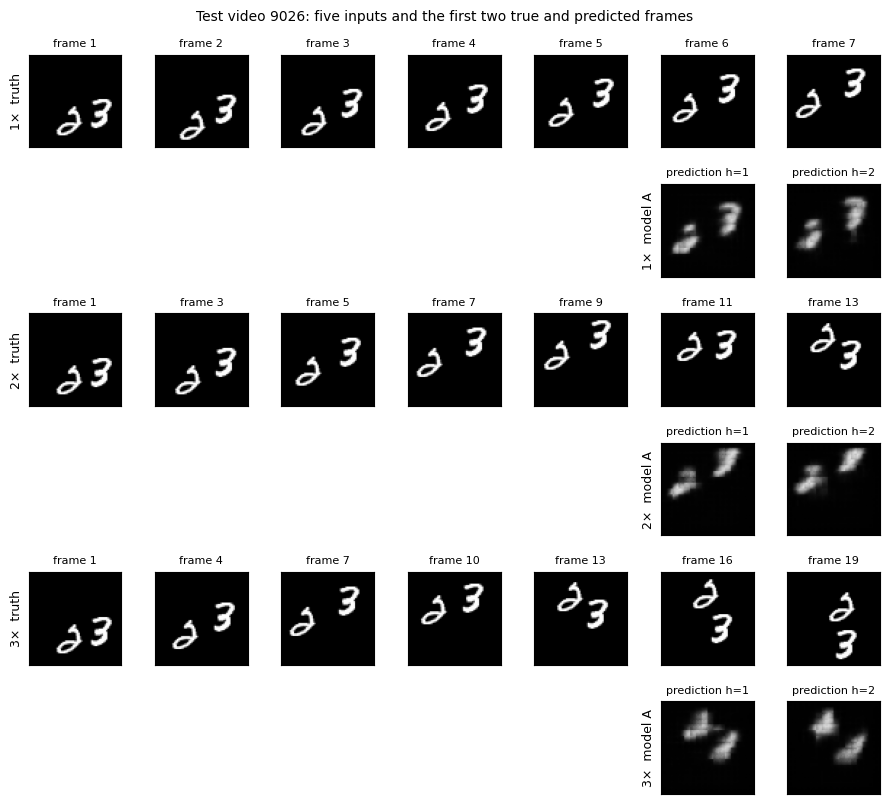

  video 9026, 1x: true jump (-1, -3), model A moves it (+0, -3)
  video 9026, 1x: true jump (-2, -3), model A moves it (-2, -3)
  video 9026, 2x: true jump (-1, +7), model A moves it (-2, -1)
  video 9026, 2x: true jump (+4, -6), model A moves it (-1, -2)
  video 9026, 3x: true jump (-2, +10), model A moves it (+0, +2)
  video 9026, 3x: true jump (+6, -2), model A moves it (+0, -1)

All non-overlapping test videos, first prediction (seed-0 model A):
  1x: 204 digits | true jump median 3.6 px | model A's jump median 3.2 px | ratio median 0.95
  2x: 196 digits | true jump median 7.1 px | model A's jump median 2.0 px | ratio median 0.28
  3x: 190 digits | true jump median 10.6 px | model A's jump median 1.4 px | ratio median 0.15


In [19]:
#  Figure 5 + how far model A moves the digits
from scipy import ndimage
from scipy.signal import fftconvolve

#  pick ing a video with no overlap in any displayed true frame
shown = {1: [1, 2, 3, 4, 5, 6, 7], 2: [1, 3, 5, 7, 9, 11, 13], 3: [1, 4, 7, 10, 13, 16, 19]}
needed = sorted(set(sum(shown.values(), [])))
area_all = (TEST_U8[:, :, 0] > 51).flatten(2).sum(-1).float()          # (1000, 20)
full_area = area_all.max(1).values
no_ovl = (area_all[:, [f - 1 for f in needed]] >= 0.97 * full_area[:, None]).all(1)
cand = torch.nonzero(no_ovl).flatten()
e1 = speed_res[("A0", 1)][cand, :2].mean(1)
order = cand[torch.argsort(e1)]
mid = len(order) // 2
V5_OVERRIDE = None                          # put a test index here to show a different video
v5 = V5_OVERRIDE if V5_OVERRIDE is not None else int(order[mid])
print(f"{len(cand)} test videos have no overlap in any displayed frame")
print(f"Figure 5 video: {9000 + v5}   (typical alternatives: "
      f"{[9000 + int(x) for x in order[mid - 3:mid + 4]]})")
torch.save(v5, f"{CKPT}/fig5_video.pt")    # Figure 6(b) must reuse this video

fig, axes = plt.subplots(6, 7, figsize=(9, 8.2))
for r, k in enumerate((1, 2, 3)):
    Xk, Yk, _ = windows_all(TEST_U8[[v5]], k=k, t=1)
    pred = predict(models_A[0], Xk)[0]
    truth = torch.cat([Xk[0, :5], Yk[0, :2]]).float() / 255
    for c in range(7):
        top, bot = axes[2 * r, c], axes[2 * r + 1, c]
        top.imshow(truth[c, 0], cmap="gray", vmin=0, vmax=1)
        top.set_title(f"frame {shown[k][c]}", fontsize=8)
        if c >= 5:
            bot.imshow(pred[c - 5, 0], cmap="gray", vmin=0, vmax=1)
            bot.set_title(f"prediction h={c - 4}", fontsize=8)
        else:
            bot.axis("off")
        for ax in (top, bot):
            ax.set_xticks([]); ax.set_yticks([])
    axes[2 * r, 0].set_ylabel(f"{k}×  truth", fontsize=9)
    axes[2 * r + 1, 5].set_ylabel(f"{k}×  model A", fontsize=9)
fig.suptitle(f"Test video {9000 + v5}: five inputs and the first two true and predicted frames",
             fontsize=10)
fig.tight_layout()
fig.savefig("/content/figure5_speed.png", dpi=200)
fig.savefig(f"{CKPT}/figure5_speed.png", dpi=200)
plt.show()

def two_digits(frame):
    """Masks of the two digits in a frame, or None if they touch."""
    lab, n = ndimage.label(frame > 0.2)
    if n < 2:
        return None
    sizes = ndimage.sum(np.ones_like(frame), lab, index=np.arange(1, n + 1))
    big = np.argsort(sizes)[::-1][:2]
    if sizes[big[1]] < 20:
        return None
    return [lab == (b + 1) for b in big]

def best_shift(template, target, R=16):
    """Shift (dx right, dy down) that best lines the template up with the target."""
    c = fftconvolve(target, template[::-1, ::-1], mode="full")
    H, W = template.shape
    c = c[H - 1 - R:H + R, W - 1 - R:W + R]
    i, j = np.unravel_index(np.argmax(c), c.shape)
    return j - R, i - R

jumps = []
for k in (1, 2, 3):
    Xk, Yk, _ = windows_all(TEST_U8, k=k, t=1)
    P = predict(models_A[0], Xk[cand])[:, 0, 0].numpy()
    for n, v in enumerate(cand.tolist()):
        last = Xk[v, 4, 0].float().numpy() / 255
        truth = Yk[v, 0, 0].float().numpy() / 255
        masks = two_digits(last)
        if masks is None:
            continue
        for m in masks:
            tx, ty = best_shift(last * m, truth)
            px, py = best_shift(last * m, P[n])
            jumps.append((k, np.hypot(tx, ty), np.hypot(px, py), v == v5))
            if v == v5:
                print(f"  video {9000 + v}, {k}x: true jump ({tx:+d}, {ty:+d}), "
                      f"model A moves it ({px:+d}, {py:+d})")
jumps = np.array(jumps)
print("\nAll non-overlapping test videos, first prediction (seed-0 model A):")
for k in (1, 2, 3):
    j = jumps[jumps[:, 0] == k]
    ratio = j[:, 2] / np.maximum(j[:, 1], 1e-6)
    print(f"  {k}x: {len(j)} digits | true jump median {np.median(j[:, 1]):.1f} px | "
          f"model A's jump median {np.median(j[:, 2]):.1f} px | ratio median {np.median(ratio):.2f}")

## 4. What can data fix?

### Model D candidates

Each candidate's one-step reach is computed with the same conventions as Q2.3, checked for
gaps and against the parameter budget (721,176). The cell also checks that symmetry
augmentation applies the same transformation to input and target.

In [20]:
#  model D candidates: reach check, budget check, augmentation check
def reach(m):
    """Longest one-step path, as in Q2.3: input -> conv1 -> conv2 -> head."""
    r = m.k // 2
    d1, d2 = m.dilations
    cells = max(r * d1 + r * d2,     # new input
                r * d1 + r * d2,     # layer 1's previous hidden state
                r * d2)              # layer 2's previous hidden state
    return cells * m.patch, cells * m.patch * np.sqrt(2)

def holes(m):
    """Offsets (in cells, per axis) the input path can NOT reach in one step."""
    r = m.k // 2
    d1, d2 = m.dilations
    offs = {a * d1 + b * d2 for a in range(-r, r + 1) for b in range(-r, r + 1)}
    return sorted(set(range(-max(offs), max(offs) + 1)) - offs)

BUDGET = 721_176
CANDIDATES = {
    "D_p4_d12": dict(patch=4, dilations=(1, 2)),
    "D_p4_d13": dict(patch=4, dilations=(1, 3)),
    "D_p8_d11": dict(patch=8, dilations=(1, 1)),
    "D_p8_d12": dict(patch=8, dilations=(1, 2)),
}
a_reach = reach(ConvLSTMForecaster())[0]
print(f"model A: reach {a_reach} px per axis\n")
for name, kw in CANDIDATES.items():
    m = ConvLSTMForecaster(**kw)
    ax_px, diag_px = reach(m)
    print(f"{name}: {n_params(m):,} params | reach {ax_px} px per axis, {diag_px:.1f} px diagonal "
          f"| holes {holes(m) or 'none'}")
    assert n_params(m) <= BUDGET and ax_px > a_reach and not holes(m)
    with torch.no_grad():
        assert m(torch.rand(2, 5, 1, 64, 64)).shape == (2, 5, 1, 64, 64)
assert n_params(ConvLSTMForecaster()) == 480_784

gen = torch.Generator().manual_seed(7)
idx = torch.randint(0, 8000, (64,), generator=gen)
state = gen.get_state()
Xp, Yp, _ = sample_windows(TRAIN_U8, idx, gen, sym_aug=False)
gen.set_state(state)
Xa, Ya, _ = sample_windows(TRAIN_U8, idx, gen, sym_aug=True)
for r in range(len(idx)):
    gs = [g for g in G if torch.equal(apply_g(Xp[r], g), Xa[r])]
    assert gs, "augmented input is not a symmetry of the plain input"
    assert any(torch.equal(apply_g(Yp[r], g), Ya[r]) for g in gs), "target got a different g"
print("\nall candidates fit the budget, beat A's reach, have no holes; "
      "symmetry augmentation uses the same g for input and target: OK")

model A: reach 8 px per axis

D_p4_d12: 480,784 params | reach 12 px per axis, 17.0 px diagonal | holes none
D_p4_d13: 480,784 params | reach 16 px per axis, 22.6 px diagonal | holes none
D_p8_d11: 594,496 params | reach 16 px per axis, 22.6 px diagonal | holes none
D_p8_d12: 594,496 params | reach 24 px per axis, 33.9 px diagonal | holes none

all candidates fit the budget, beat A's reach, have no holes; symmetry augmentation uses the same g for input and target: OK


### Models B (symmetry augmentation) and C (speed augmentation)

In [21]:
#  train B (symmetry augmentation) and C
models_B, info_B, models_C, info_C = {}, {}, {}, {}
for seed in (0, 1):
    models_B[seed], info_B[seed] = train(ConvLSTMForecaster, seed, "B", sym_aug=True, ckpt_dir=CKPT)
for seed in (0, 1):
    models_C[seed], info_C[seed] = train(ConvLSTMForecaster, seed, "C", speed_aug=True, ckpt_dir=CKPT)

B seed 0 | epoch  1/30 | train 0.04610 | val E(5) 0.03931 | 1.8 s
B seed 0 | epoch  2/30 | train 0.03966 | val E(5) 0.03852 | 1.8 s
B seed 0 | epoch  3/30 | train 0.03865 | val E(5) 0.03730 | 1.8 s
B seed 0 | epoch  4/30 | train 0.03707 | val E(5) 0.03559 | 1.8 s
B seed 0 | epoch  5/30 | train 0.03527 | val E(5) 0.03390 | 1.8 s
B seed 0 | epoch  6/30 | train 0.03368 | val E(5) 0.03252 | 1.8 s
B seed 0 | epoch  7/30 | train 0.03247 | val E(5) 0.03217 | 1.8 s
B seed 0 | epoch  8/30 | train 0.03139 | val E(5) 0.03059 | 1.8 s
B seed 0 | epoch  9/30 | train 0.03052 | val E(5) 0.02982 | 1.8 s
B seed 0 | epoch 10/30 | train 0.03009 | val E(5) 0.02930 | 1.8 s
B seed 0 | epoch 11/30 | train 0.02947 | val E(5) 0.02894 | 1.8 s
B seed 0 | epoch 12/30 | train 0.02905 | val E(5) 0.02855 | 1.8 s
B seed 0 | epoch 13/30 | train 0.02855 | val E(5) 0.02885 | 1.8 s
B seed 0 | epoch 14/30 | train 0.02818 | val E(5) 0.02770 | 1.8 s
B seed 0 | epoch 15/30 | train 0.02777 | val E(5) 0.02742 | 1.8 s
B seed 0 |

### Choosing model D on the validation split only

Rule fixed in advance: lowest validation $E^{(2)}$ averaged over $1\times$, $2\times$ and
$3\times$ (supplementary Table S1). The test split is not used here.

In [22]:
#  pick model D on VALIDATION only
@torch.no_grad()
def val_scores(model):
    out = {}
    for k in (1, 2, 3):
        Xk, Yk, vk = windows_all(VAL_U8, k=k, t=1)
        m = per_video_mse(predict(model, Xk), Yk, vk)
        out[f"{k}x"] = m[:, :2].mean().item()
        if k == 1:
            out["E5"] = m.mean().item()
    out["score"] = np.mean([out["1x"], out["2x"], out["3x"]])
    return out

cand_models, cand_scores = {}, {"C (reference)": val_scores(models_C[0])}
for name, kw in CANDIDATES.items():
    cand_models[name], _ = train(lambda kw=kw: ConvLSTMForecaster(**kw), 0, name,
                                 speed_aug=True, ckpt_dir=CKPT)
    cand_scores[name] = val_scores(cand_models[name])

print(f"\n{'validation, seed 0':18s} {'E(2) 1x':>9s} {'E(2) 2x':>9s} {'E(2) 3x':>9s} "
      f"{'E(5) 1x':>9s} {'score':>9s}")
for name, s in cand_scores.items():
    print(f"{name:18s} {s['1x']:9.4f} {s['2x']:9.4f} {s['3x']:9.4f} {s['E5']:9.4f} {s['score']:9.4f}")
D_NAME = min(CANDIDATES, key=lambda n: cand_scores[n]["score"])
print(f"\nchosen model D: {D_NAME}  (lowest mean validation E(2) over 1x, 2x, 3x)")
torch.save({"scores": cand_scores, "chosen": D_NAME}, f"{CKPT}/D_selection.pt")

D_p4_d12 seed 0 | epoch  1/30 | train 0.04654 | val E(5) 0.03918 | 1.5 s
D_p4_d12 seed 0 | epoch  2/30 | train 0.03975 | val E(5) 0.03889 | 1.5 s
D_p4_d12 seed 0 | epoch  3/30 | train 0.03930 | val E(5) 0.03819 | 1.5 s
D_p4_d12 seed 0 | epoch  4/30 | train 0.03851 | val E(5) 0.03722 | 1.5 s
D_p4_d12 seed 0 | epoch  5/30 | train 0.03779 | val E(5) 0.03642 | 1.5 s
D_p4_d12 seed 0 | epoch  6/30 | train 0.03703 | val E(5) 0.03553 | 1.5 s
D_p4_d12 seed 0 | epoch  7/30 | train 0.03633 | val E(5) 0.03482 | 1.5 s
D_p4_d12 seed 0 | epoch  8/30 | train 0.03572 | val E(5) 0.03412 | 1.5 s
D_p4_d12 seed 0 | epoch  9/30 | train 0.03528 | val E(5) 0.03390 | 1.5 s
D_p4_d12 seed 0 | epoch 10/30 | train 0.03492 | val E(5) 0.03315 | 1.5 s
D_p4_d12 seed 0 | epoch 11/30 | train 0.03440 | val E(5) 0.03361 | 1.5 s
D_p4_d12 seed 0 | epoch 12/30 | train 0.03409 | val E(5) 0.03242 | 1.5 s
D_p4_d12 seed 0 | epoch 13/30 | train 0.03382 | val E(5) 0.03180 | 1.5 s
D_p4_d12 seed 0 | epoch 14/30 | train 0.03342 | val

In [23]:
# ============ final model D, seeds 0 and 1 ============
models_D, info_D = {}, {}
for seed in (0, 1):
    models_D[seed], info_D[seed] = train(lambda: ConvLSTMForecaster(**CANDIDATES[D_NAME]), seed,
                                         D_NAME, speed_aug=True, ckpt_dir=CKPT)

resuming D_p4_d12 seed 0 from epoch 30
D_p4_d12 seed 1 | epoch  1/30 | train 0.04832 | val E(5) 0.03948 | 1.5 s
D_p4_d12 seed 1 | epoch  2/30 | train 0.04021 | val E(5) 0.03947 | 1.5 s
D_p4_d12 seed 1 | epoch  3/30 | train 0.04018 | val E(5) 0.03947 | 1.5 s
D_p4_d12 seed 1 | epoch  4/30 | train 0.04007 | val E(5) 0.03923 | 1.5 s
D_p4_d12 seed 1 | epoch  5/30 | train 0.03981 | val E(5) 0.03892 | 1.5 s
D_p4_d12 seed 1 | epoch  6/30 | train 0.03943 | val E(5) 0.03849 | 1.5 s
D_p4_d12 seed 1 | epoch  7/30 | train 0.03847 | val E(5) 0.03690 | 1.5 s
D_p4_d12 seed 1 | epoch  8/30 | train 0.03731 | val E(5) 0.03621 | 1.5 s
D_p4_d12 seed 1 | epoch  9/30 | train 0.03627 | val E(5) 0.03443 | 1.5 s
D_p4_d12 seed 1 | epoch 10/30 | train 0.03539 | val E(5) 0.03348 | 1.5 s
D_p4_d12 seed 1 | epoch 11/30 | train 0.03457 | val E(5) 0.03263 | 1.5 s
D_p4_d12 seed 1 | epoch 12/30 | train 0.03391 | val E(5) 0.03174 | 1.5 s
D_p4_d12 seed 1 | epoch 13/30 | train 0.03343 | val E(5) 0.03100 | 1.5 s
D_p4_d12 see

### Table 5: models A–D

In [24]:
@torch.no_grad()
def inference_time(model, bs=32):
    model.eval()
    model(Xt[:bs].to(device).float() / 255)          # warm-up, not timed
    total = 0.0
    for s in range(0, len(Xt), bs):
        xb = Xt[s:s + bs].to(device).float() / 255
        sync(); t0 = time.perf_counter()
        model(xb)
        sync(); total += time.perf_counter() - t0
    return total

def full_eval(model):
    r = consistency_tests(model)
    out = {k: r[k].mean().item() for k in ("E5", "CM", "EM", "CR", "ER")}
    for k in (1, 2, 3):
        Xk, Yk, vk = windows_all(TEST_U8, k=k, t=1)
        out[f"E2_{k}x"] = per_video_mse(predict(model, Xk), Yk, vk)[:, :2].mean().item()
    out["infer"] = inference_time(model)
    return out

all_models = {"A": models_A, "B": models_B, "C": models_C, "D": models_D}
all_info = {"A": info_A, "B": info_B, "C": info_C, "D": info_D}
t5 = {(n, s): full_eval(all_models[n][s]) for n in all_models for s in (0, 1)}
for n in all_models:
    for s in (0, 1):
        t5[(n, s)]["train"] = all_info[n][s]["epoch_time"]

rows5 = [("E5", "$E^{(5)}$ at $1\\times$"), ("CM", "$C_M$"), ("EM", "$E_M$"),
         ("CR", "$C_R$"), ("ER", "$E_R$"), ("E2_1x", "$E^{(2)}$ at $1\\times$"),
         ("E2_2x", "$E^{(2)}$ at $2\\times$"), ("E2_3x", "$E^{(2)}$ at $3\\times$"),
         ("train", "Training time per epoch (s)"), ("infer", "Inference time (s)")]
names = list(all_models)
print(r"\begin{table}[H]")
print(r"\centering")
print(r"\caption{Models A--D on the test set. Each entry: mean (seed 0, seed 1).}")
print(r"\label{tab:table5}")
print(r"\resizebox{\textwidth}{!}{%")
print(r"\begin{tabular}{l" + "c" * len(names) + "}")
print(r"\toprule")
print(" & " + " & ".join(f"Model {n}" for n in names) + r" \\")
print(r"\midrule")
for key, label in rows5:
    if key in ("E2_1x", "train"):
        print(r"\midrule")
    cells = []
    for n in names:
        a, b = t5[(n, 0)][key], t5[(n, 1)][key]
        cells.append(f"{fmt((a + b) / 2)} ({fmt(a)}, {fmt(b)})")
    print(f"{label} & " + " & ".join(cells) + r" \\")
print("Parameters & " + " & ".join(f"{n_params(all_models[n][0]):,}".replace(",", "{,}")
                                   for n in names) + r" \\")
print(r"\bottomrule")
print(r"\end{tabular}}")
print(r"\end{table}")
print("\nhardware:", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU")
torch.save(t5, f"{CKPT}/table5_results.pt")

\begin{table}[H]
\centering
\caption{Models A--D on the test set. Each entry: mean (seed 0, seed 1).}
\label{tab:table5}
\resizebox{\textwidth}{!}{%
\begin{tabular}{lcccc}
\toprule
 & Model A & Model B & Model C & Model D \\
\midrule
$E^{(5)}$ at $1\times$ & 0.0222 (0.0225, 0.0218) & 0.0227 (0.0232, 0.0223) & 0.0270 (0.0272, 0.0268) & 0.0273 (0.0277, 0.0270) \\
$C_M$ & 0.00190 (0.00180, 0.00201) & 0.00141 (0.00122, 0.00160) & 0.00111 (0.00101, 0.00122) & 7.81e-04 (6.33e-04, 9.29e-04) \\
$E_M$ & 0.0228 (0.0232, 0.0224) & 0.0228 (0.0233, 0.0223) & 0.0272 (0.0274, 0.0270) & 0.0275 (0.0278, 0.0272) \\
$C_R$ & 0.00321 (0.00340, 0.00301) & 0.00147 (0.00138, 0.00156) & 0.00244 (0.00227, 0.00260) & 0.00181 (0.00163, 0.00199) \\
$E_R$ & 0.0238 (0.0242, 0.0234) & 0.0227 (0.0232, 0.0222) & 0.0282 (0.0283, 0.0280) & 0.0284 (0.0286, 0.0282) \\
\midrule
$E^{(2)}$ at $1\times$ & 0.0188 (0.0189, 0.0186) & 0.0191 (0.0194, 0.0188) & 0.0234 (0.0237, 0.0230) & 0.0246 (0.0248, 0.0243) \\
$E^{(2)}$ at $2\ti

## 5. The final model

### D+B, the symmetrised forecaster, and Table 6

The wrapper averages $g^{-1}(f(g(X)))$ over all eight symmetries. Its exactness is checked
first on an untrained model, since the gap must vanish for any $f$.

In [25]:
#  train D+B (speed + symmetry augmentation)
D_KW = dict(patch=4, dilations=(1, 2))          # i  chose model D (D_p4_d12)
models_DB, info_DB = {}, {}
for seed in (0, 1):
    models_DB[seed], info_DB[seed] = train(lambda: ConvLSTMForecaster(**D_KW), seed, "DB",
                                           speed_aug=True, sym_aug=True, ckpt_dir=CKPT)

DB seed 0 | epoch  1/30 | train 0.04653 | val E(5) 0.03912 | 1.8 s
DB seed 0 | epoch  2/30 | train 0.03962 | val E(5) 0.03863 | 1.8 s
DB seed 0 | epoch  3/30 | train 0.03883 | val E(5) 0.03763 | 1.8 s
DB seed 0 | epoch  4/30 | train 0.03795 | val E(5) 0.03668 | 1.8 s
DB seed 0 | epoch  5/30 | train 0.03710 | val E(5) 0.03619 | 1.8 s
DB seed 0 | epoch  6/30 | train 0.03631 | val E(5) 0.03438 | 1.8 s
DB seed 0 | epoch  7/30 | train 0.03557 | val E(5) 0.03368 | 1.8 s
DB seed 0 | epoch  8/30 | train 0.03492 | val E(5) 0.03329 | 1.8 s
DB seed 0 | epoch  9/30 | train 0.03435 | val E(5) 0.03250 | 1.8 s
DB seed 0 | epoch 10/30 | train 0.03385 | val E(5) 0.03160 | 1.8 s
DB seed 0 | epoch 11/30 | train 0.03348 | val E(5) 0.03098 | 1.8 s
DB seed 0 | epoch 12/30 | train 0.03310 | val E(5) 0.03120 | 1.8 s
DB seed 0 | epoch 13/30 | train 0.03294 | val E(5) 0.03062 | 1.8 s
DB seed 0 | epoch 14/30 | train 0.03265 | val E(5) 0.02989 | 1.8 s
DB seed 0 | epoch 15/30 | train 0.03233 | val E(5) 0.02959 | 1

In [26]:
# symmetrised forecaster + Table 6
class Symmetrised(nn.Module):
    """f_bar(X) = (1/8) * sum over g of g^-1( f( g(X) ) )."""
    def __init__(self, base):
        super().__init__()
        self.base = base

    def forward(self, X):
        B = X.shape[0]
        Xg = torch.cat([apply_g(X, g) for g in G])        # all 8 orientations, one batch
        Pg = self.base(Xg).split(B)
        return torch.stack([invert_g(p, g) for p, g in zip(Pg, G)]).mean(0)

def g_name(g):
    m, a = g
    return ("M" if m else "") + (f"R^{a}" if a else ("" if m else "identity"))

torch.manual_seed(0)
rand_f = ConvLSTMForecaster(**D_KW).to(device).eval()
sym_rand = Symmetrised(rand_f).eval()
Xr = torch.rand(4, 5, 1, 64, 64, device=device)
with torch.no_grad():
    plain_out, sym_out = rand_f(Xr), sym_rand(Xr)
    print(f"{'h':10s} {'max gap, plain f':>18s} {'max gap, symmetrised':>22s}")
    for h in G:
        d_plain = (rand_f(apply_g(Xr, h)) - apply_g(plain_out, h)).abs().max().item()
        d_sym = (sym_rand(apply_g(Xr, h)) - apply_g(sym_out, h)).abs().max().item()
        print(f"{g_name(h):10s} {d_plain:18.2e} {d_sym:22.2e}")

wrapped = {
    "Sym.\\ B":           ({s: Symmetrised(models_B[s]) for s in (0, 1)}, info_B),
    "Sym.\\ D":           ({s: Symmetrised(models_D[s]) for s in (0, 1)}, info_D),
    "Final: sym.\\ D+B":  ({s: Symmetrised(models_DB[s]) for s in (0, 1)}, info_DB),
    "D+B (unwrapped)":    (models_DB, info_DB),
}
t6 = {}
for name, (ms, info) in wrapped.items():
    for s in (0, 1):
        t6[(name, s)] = full_eval(ms[s])
        t6[(name, s)]["train"] = info[s]["epoch_time"]

names6 = list(wrapped)
print("\n" + r"\begin{table}[H]")
print(r"\centering")
print(r"\caption{Symmetrised models and the final model on the test set. Each entry: mean "
      r"(seed 0, seed 1). Training time is that of the underlying learned model; inference "
      r"time includes all eight transformations, forward passes, inverse transformations and "
      r"the averaging. D+B without the wrapper is shown for reference.}")
print(r"\label{tab:table6}")
print(r"\resizebox{\textwidth}{!}{%")
print(r"\begin{tabular}{l" + "c" * len(names6) + "}")
print(r"\toprule")
print(" & " + " & ".join(names6) + r" \\")
print(r"\midrule")
for key, label in rows5:
    if key in ("E2_1x", "train"):
        print(r"\midrule")
    cells = []
    for n in names6:
        a, b = t6[(n, 0)][key], t6[(n, 1)][key]
        cells.append(f"{fmt((a + b) / 2)} ({fmt(a)}, {fmt(b)})")
    print(f"{label} & " + " & ".join(cells) + r" \\")
print("Parameters & " + " & ".join(f"{n_params(wrapped[n][0][0]):,}".replace(",", "{,}")
                                   for n in names6) + r" \\")
print(r"\bottomrule")
print(r"\end{tabular}}")
print(r"\end{table}")

for n in names6:
    m = lambda k: (t6[(n, 0)][k] + t6[(n, 1)][k]) / 2
    print(f"{n.replace(chr(92), ''):20s} E_R/E(5) = {m('ER') / m('E5'):.3f}   "
          f"E_M/E(5) = {m('EM') / m('E5'):.3f}   inference {m('infer'):.3g} s")
torch.save(t6, f"{CKPT}/table6_results.pt")
final_models = wrapped["Final: sym.\\ D+B"][0]

h            max gap, plain f   max gap, symmetrised
identity             0.00e+00               0.00e+00
R^1                  4.43e-02               5.96e-08
R^2                  4.39e-02               5.96e-08
R^3                  4.41e-02               5.96e-08
M                    4.69e-02               5.96e-08
MR^1                 4.68e-02               5.96e-08
MR^2                 4.71e-02               5.96e-08
MR^3                 4.64e-02               5.96e-08

\begin{table}[H]
\centering
\caption{Symmetrised models and the final model on the test set. Each entry: mean (seed 0, seed 1). Training time is that of the underlying learned model; inference time includes all eight transformations, forward passes, inverse transformations and the averaging. D+B without the wrapper is shown for reference.}
\label{tab:table6}
\resizebox{\textwidth}{!}{%
\begin{tabular}{lcccc}
\toprule
 & Sym.\ B & Sym.\ D & Final: sym.\ D+B & D+B (unwrapped) \\
\midrule
$E^{(5)}$ at $1\times$ & 0.0221

### Figure 6(a) and GIFs: the Figure 3 videos again, with the final model

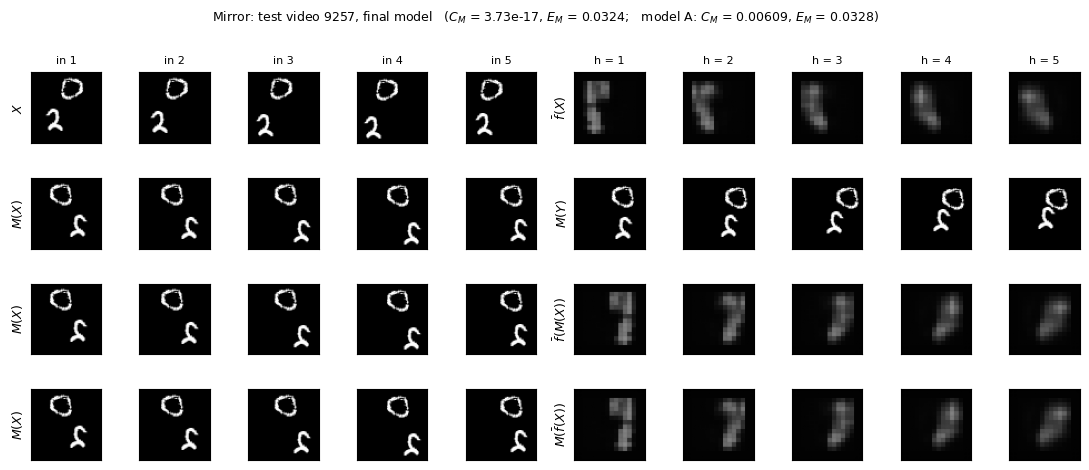

saved /content/drive/MyDrive/dl4stg_q2_v2/gifs/fig6a_M_video9257.gif


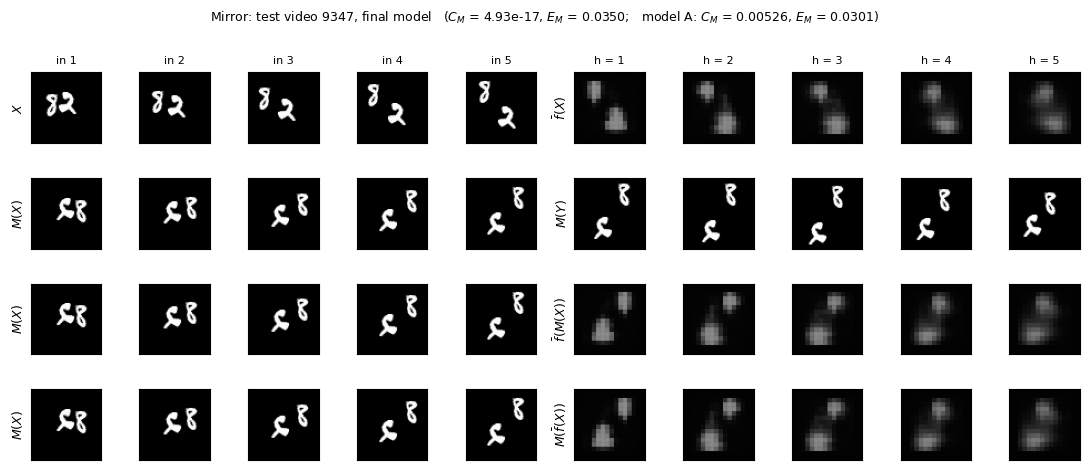

saved /content/drive/MyDrive/dl4stg_q2_v2/gifs/fig6a_M_video9347.gif


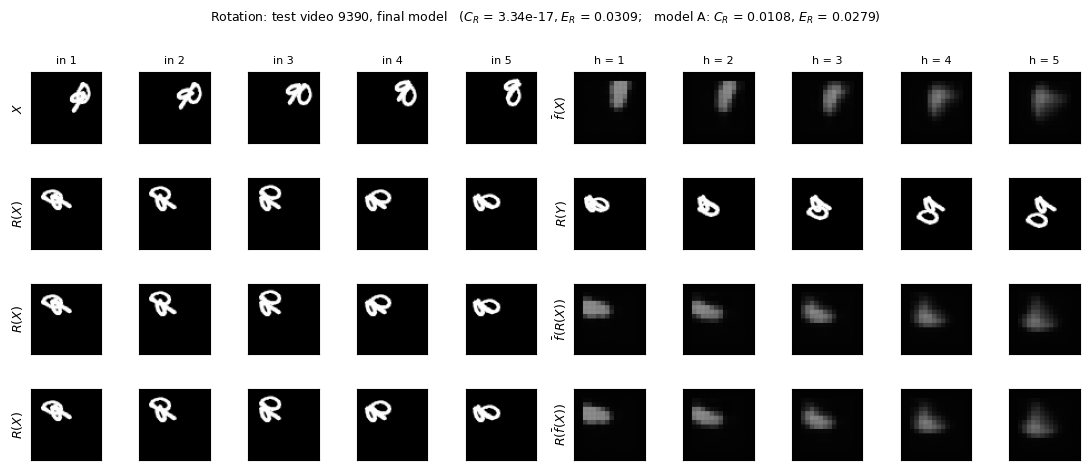

saved /content/drive/MyDrive/dl4stg_q2_v2/gifs/fig6a_R_video9390.gif


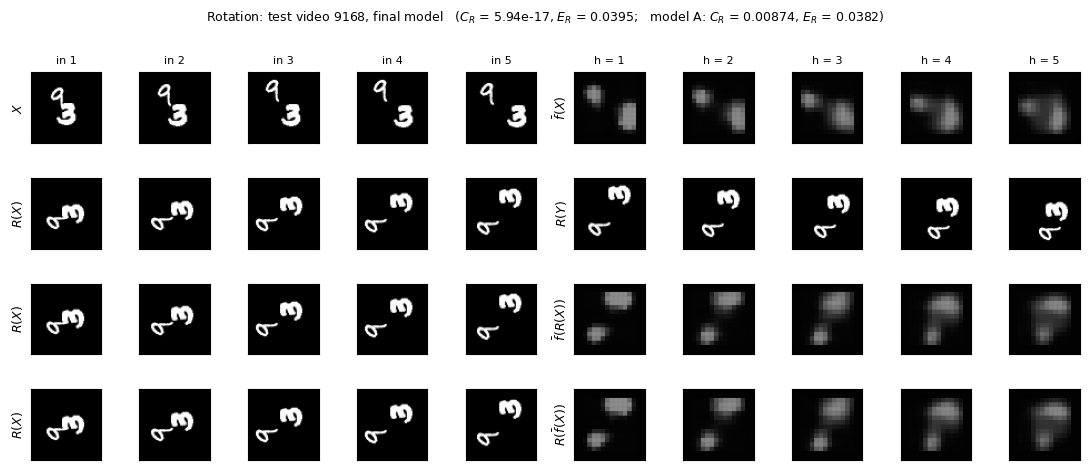

saved /content/drive/MyDrive/dl4stg_q2_v2/gifs/fig6a_R_video9168.gif


In [27]:
#  Figure 6(a) + GIFs (same videos as Figure 3)
from PIL import Image
picks = torch.load(f"{CKPT}/fig3_picks.pt")
t3 = torch.load(f"{CKPT}/table3_per_video.pt", weights_only=False)
GIF_DIR = f"{CKPT}/gifs"
os.makedirs(GIF_DIR, exist_ok=True)
final0 = final_models[0]

def fig_to_image(fig):
    fig.canvas.draw()
    img = Image.fromarray(np.asarray(fig.canvas.buffer_rgba())[..., :3].copy())
    plt.close(fig)
    return img

def panel(predictor, name, v):
    T = TRANSFORMS[name]
    X = Xt[[v]]
    fX, fTX = predict(predictor, X)[0], predict(predictor, T(X))[0]
    X01, Y = X[0].float() / 255, Y01[v]
    rows = [(X01, fX), (T(X01), T(Y)), (T(X01), fTX), (T(X01), T(fX))]
    labels = [(r"$X$", r"$\bar f(X)$"), (f"${name}(X)$", f"${name}(Y)$"),
              (f"${name}(X)$", rf"$\bar f({name}(X))$"),
              (f"${name}(X)$", rf"${name}(\bar f(X))$")]
    C = ((fTX - T(fX)) ** 2).mean().item()
    E = ((fTX - T(Y)) ** 2).mean().item()
    return rows, labels, C, E

for name, v in picks:
    rows, labels, C, E = panel(final0, name, v)
    word = "Mirror" if name == "M" else "Rotation"
    cA, eA = t3["A0"][f"C{name}"][v].item(), t3["A0"][f"E{name}"][v].item()

    fig, axes = plt.subplots(4, 10, figsize=(11, 4.9))
    for i, ((left, right), (ll, rl)) in enumerate(zip(rows, labels)):
        for c in range(10):
            axes[i, c].imshow(left[c, 0] if c < 5 else right[c - 5, 0], cmap="gray", vmin=0, vmax=1)
            axes[i, c].set_xticks([]); axes[i, c].set_yticks([])
        axes[i, 0].set_ylabel(ll, fontsize=9)
        axes[i, 5].set_ylabel(rl, fontsize=9)
    for c in range(10):
        axes[0, c].set_title(f"in {c + 1}" if c < 5 else f"h = {c - 4}", fontsize=8)
    fig.suptitle(f"{word}: test video {9000 + v}, final model   "
                 f"($C_{name}$ = {fmt(C)}, $E_{name}$ = {fmt(E)};   "
                 f"model A: $C_{name}$ = {fmt(cA)}, $E_{name}$ = {fmt(eA)})", fontsize=9)
    fig.tight_layout()
    png = f"fig6a_{name}_video{9000 + v}.png"
    fig.savefig(f"/content/{png}", dpi=200); fig.savefig(f"{CKPT}/{png}", dpi=200)
    plt.show()

    frames = []
    for h in range(5):
        fig, axes = plt.subplots(4, 1, figsize=(2.8, 9.2))
        for ax, (_, right), (_, rl) in zip(axes, rows, labels):
            ax.imshow(right[h, 0], cmap="gray", vmin=0, vmax=1)
            ax.set_title(rl, fontsize=10); ax.set_xticks([]); ax.set_yticks([])
        fig.suptitle(f"video {9000 + v} · {word.lower()} · final · horizon {h + 1}", fontsize=8)
        fig.tight_layout()
        frames.append(fig_to_image(fig))
    path = f"{GIF_DIR}/fig6a_{name}_video{9000 + v}.gif"
    frames[0].save(path, save_all=True, append_images=frames[1:], duration=800, loop=0)
    print("saved", path)

### Figure 6(b) and digit jumps for models A, C and the final model

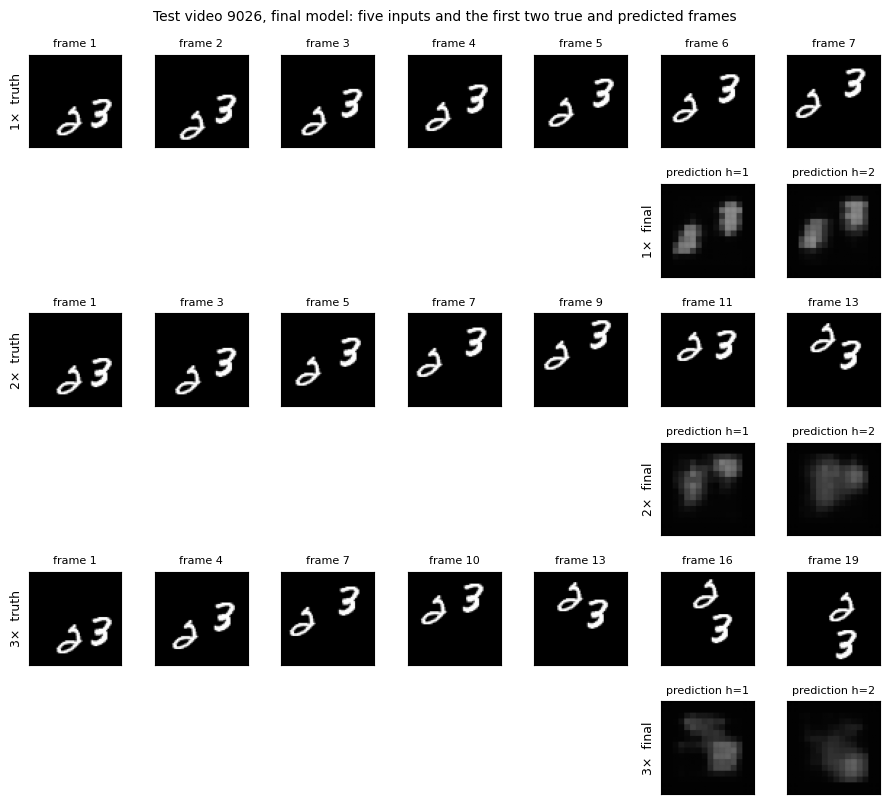

Median digit jump in the first prediction (non-overlapping test videos):
  model A      1x: true   3.6 px | model   3.2 px | ratio 0.95
  model A      2x: true   7.1 px | model   2.0 px | ratio 0.28
  model A      3x: true  10.6 px | model   1.4 px | ratio 0.15
  model C      1x: true   3.6 px | model   3.2 px | ratio 0.88
  model C      2x: true   7.1 px | model   7.1 px | ratio 1.01
  model C      3x: true  10.6 px | model   8.1 px | ratio 0.82
  final        1x: true   3.6 px | model   3.2 px | ratio 0.93
  final        2x: true   7.1 px | model   7.3 px | ratio 1.09
  final        3x: true  10.6 px | model   8.5 px | ratio 0.88


In [28]:
# Figure 6(b) + digit jumps for A, C and the final model
from scipy import ndimage
from scipy.signal import fftconvolve

v5 = torch.load(f"{CKPT}/fig5_video.pt")
shown = {1: [1, 2, 3, 4, 5, 6, 7], 2: [1, 3, 5, 7, 9, 11, 13], 3: [1, 4, 7, 10, 13, 16, 19]}

fig, axes = plt.subplots(6, 7, figsize=(9, 8.2))
for r, k in enumerate((1, 2, 3)):
    Xk, Yk, _ = windows_all(TEST_U8[[v5]], k=k, t=1)
    pred = predict(final0, Xk)[0]
    truth = torch.cat([Xk[0, :5], Yk[0, :2]]).float() / 255
    for c in range(7):
        top, bot = axes[2 * r, c], axes[2 * r + 1, c]
        top.imshow(truth[c, 0], cmap="gray", vmin=0, vmax=1)
        top.set_title(f"frame {shown[k][c]}", fontsize=8)
        if c >= 5:
            bot.imshow(pred[c - 5, 0], cmap="gray", vmin=0, vmax=1)
            bot.set_title(f"prediction h={c - 4}", fontsize=8)
        else:
            bot.axis("off")
        for ax in (top, bot):
            ax.set_xticks([]); ax.set_yticks([])
    axes[2 * r, 0].set_ylabel(f"{k}×  truth", fontsize=9)
    axes[2 * r + 1, 5].set_ylabel(f"{k}×  final", fontsize=9)
fig.suptitle(f"Test video {9000 + v5}, final model: five inputs and the first two true and "
             f"predicted frames", fontsize=10)
fig.tight_layout()
fig.savefig("/content/figure6b_speed_final.png", dpi=200)
fig.savefig(f"{CKPT}/figure6b_speed_final.png", dpi=200)
plt.show()

#  digit jumps, as in the Figure 5 cell
def two_digits(frame):
    lab, n = ndimage.label(frame > 0.2)
    if n < 2:
        return None
    sizes = ndimage.sum(np.ones_like(frame), lab, index=np.arange(1, n + 1))
    big = np.argsort(sizes)[::-1][:2]
    return None if sizes[big[1]] < 20 else [lab == (b + 1) for b in big]

def best_shift(template, target, R=16):
    c = fftconvolve(target, template[::-1, ::-1], mode="full")
    H, W = template.shape
    c = c[H - 1 - R:H + R, W - 1 - R:W + R]
    i, j = np.unravel_index(np.argmax(c), c.shape)
    return j - R, i - R

needed = sorted(set(sum(shown.values(), [])))
area_all = (TEST_U8[:, :, 0] > 51).flatten(2).sum(-1).float()
full_area = area_all.max(1).values
cand = torch.nonzero((area_all[:, [f - 1 for f in needed]] >= 0.97 * full_area[:, None]).all(1)).flatten()

def jump_table(predictor, label):
    for k in (1, 2, 3):
        Xk, Yk, _ = windows_all(TEST_U8, k=k, t=1)
        P = predict(predictor, Xk[cand])[:, 0, 0].numpy()
        tj, pj = [], []
        for n, v in enumerate(cand.tolist()):
            last = Xk[v, 4, 0].float().numpy() / 255
            masks = two_digits(last)
            if masks is None:
                continue
            truth = Yk[v, 0, 0].float().numpy() / 255
            for m in masks:
                tj.append(np.hypot(*best_shift(last * m, truth)))
                pj.append(np.hypot(*best_shift(last * m, P[n])))
        tj, pj = np.array(tj), np.array(pj)
        print(f"  {label:12s} {k}x: true {np.median(tj):5.1f} px | model {np.median(pj):5.1f} px | "
              f"ratio {np.median(pj / np.maximum(tj, 1e-6)):.2f}")

print("Median digit jump in the first prediction (non-overlapping test videos):")
for label, p in (("model A", models_A[0]), ("model C", models_C[0]), ("final", final0)):
    jump_table(p, label)

### Video 9257 (Q2.7) under every model, for Q2.16

In [29]:
#  video 9257 (Q2.7) under every model
Q27 = 257                                   # test index of video 9257
T = TRANSFORMS["M"]
X, Y = Xt[[Q27]], Y01[Q27]
print(f"{'model':16s} {'E (normal)':>11s} {'E_M':>9s} {'C_M':>10s}   brightness of f(M(X)) per horizon")
for label, p in (("A", models_A[0]), ("B", models_B[0]), ("C", models_C[0]), ("D", models_D[0]),
                 ("D+B", models_DB[0]), ("final", final0)):
    fX, fTX = predict(p, X)[0], predict(p, T(X))[0]
    bright = (fTX.sum(dim=(1, 2, 3)) / T(Y).sum(dim=(1, 2, 3))).numpy()
    print(f"{label:16s} {((fX - Y) ** 2).mean().item():11.4f} "
          f"{((fTX - T(Y)) ** 2).mean().item():9.4f} {fmt(((fTX - T(fX)) ** 2).mean().item()):>10s}   "
          + " ".join(f"{b:.2f}" for b in bright))

model             E (normal)       E_M        C_M   brightness of f(M(X)) per horizon
A                     0.0258    0.0328    0.00609   1.16 1.15 1.06 0.90 0.98
B                     0.0286    0.0268    0.00228   1.17 1.13 1.07 1.05 1.06
C                     0.0337    0.0347    0.00112   1.32 1.34 1.26 1.23 1.30
D                     0.0328    0.0342   7.48e-04   1.28 1.30 1.26 1.16 1.08
D+B                   0.0319    0.0338   7.98e-04   1.32 1.20 1.12 1.13 1.13
final                 0.0324    0.0324   3.73e-17   1.29 1.22 1.13 1.09 1.08
